In [1]:
!pip install pandas

In [ ]:
#==================
# Combined Dataset
#==================

In [2]:

import pandas as pd
from urllib.request import urlopen, Request

BASE_URL = (
    "https://archive.ics.uci.edu/"
    "ml/machine-learning-databases/adult/"
)

columns = [
    "age", "workclass", "fnlwgt", "education", "education_num",
    "marital_status", "occupation", "relationship", "race", "sex",
    "capital_gain", "capital_loss", "hours_per_week",
    "native_country", "income"
]


def download_file(filename):
    url = BASE_URL + filename
    request = Request(url, headers={"User-Agent": "Mozilla/5.0"})

    with urlopen(request, timeout=30) as response:
        data = response.read()

    with open(filename, "wb") as file:
        file.write(data)

    print(f"Downloaded: {filename}")


# 1. Download the original UCI files
download_file("adult.data")
download_file("adult.test")
download_file("adult.names")

# 2. Load the training dataset
train = pd.read_csv(
    "adult.data",
    header=None,
    names=columns,
    skipinitialspace=True
)

# 3. Load the test dataset
test = pd.read_csv(
    "adult.test",
    header=None,
    names=columns,
    skiprows=1,
    skipinitialspace=True
)

# 4. Clean whitespace and income labels
for df in (train, test):
    for col in df.select_dtypes(include="object").columns:
        df[col] = df[col].str.strip()

    df["income"] = df["income"].str.rstrip(".")

# 5. Combine both datasets
combined = pd.concat([train, test], ignore_index=True)

# 6. Replace missing-value markers
combined.replace("?", pd.NA, inplace=True)

# 7. Export the combined dataset
combined.to_csv("adult_combined.csv", index=False)

# 8. Display results
print("\nDataset combined successfully!")
print("Training rows:", len(train))
print("Test rows:", len(test))
print("Combined shape:", combined.shape)
print("\nIncome distribution:")
print(combined["income"].value_counts(dropna=False))
print("\nFirst 5 records:")
print(combined.head())

print("\nOutput file: adult_combined.csv")


Downloaded: adult.data
Downloaded: adult.test
Downloaded: adult.names

Dataset combined successfully!
Training rows: 32561
Test rows: 16281
Combined shape: (48842, 15)

Income distribution:
income
<=50K    37155
>50K     11687
Name: count, dtype: int64

First 5 records:
   age         workclass  fnlwgt  education  education_num  \
0   39         State-gov   77516  Bachelors             13   
1   50  Self-emp-not-inc   83311  Bachelors             13   
2   38           Private  215646    HS-grad              9   
3   53           Private  234721       11th              7   
4   28           Private  338409  Bachelors             13   

       marital_status         occupation   relationship   race     sex  \
0       Never-married       Adm-clerical  Not-in-family  White    Male   
1  Married-civ-spouse    Exec-managerial        Husband  White    Male   
2            Divorced  Handlers-cleaners  Not-in-family  White    Male   
3  Married-civ-spouse  Handlers-cleaners        Husband  Bla

In [ ]:
#================
# EDA
#===============

1. DATASET OVERVIEW
Shape: (48842, 15)

First 5 rows:
    age         workclass  fnlwgt  education  education_num  \
0   39         State-gov   77516  Bachelors             13   
1   50  Self-emp-not-inc   83311  Bachelors             13   
2   38           Private  215646    HS-grad              9   
3   53           Private  234721       11th              7   
4   28           Private  338409  Bachelors             13   

       marital_status         occupation   relationship   race     sex  \
0       Never-married       Adm-clerical  Not-in-family  White    Male   
1  Married-civ-spouse    Exec-managerial        Husband  White    Male   
2            Divorced  Handlers-cleaners  Not-in-family  White    Male   
3  Married-civ-spouse  Handlers-cleaners        Husband  Black    Male   
4  Married-civ-spouse     Prof-specialty           Wife  Black  Female   

   capital_gain  capital_loss  hours_per_week native_country income  
0          2174             0              40  United-Sta

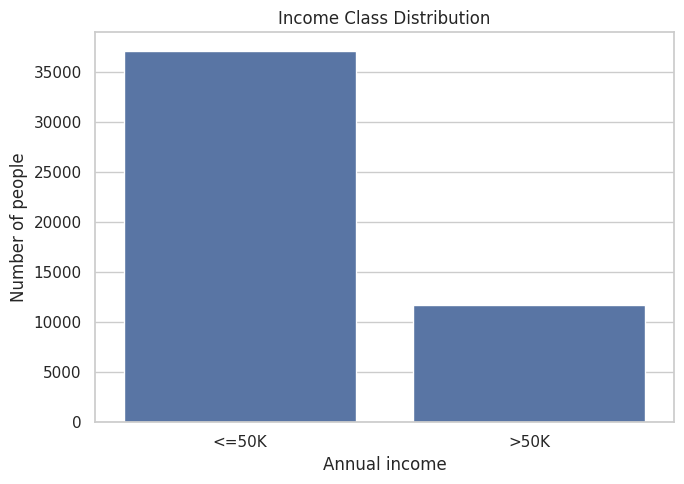

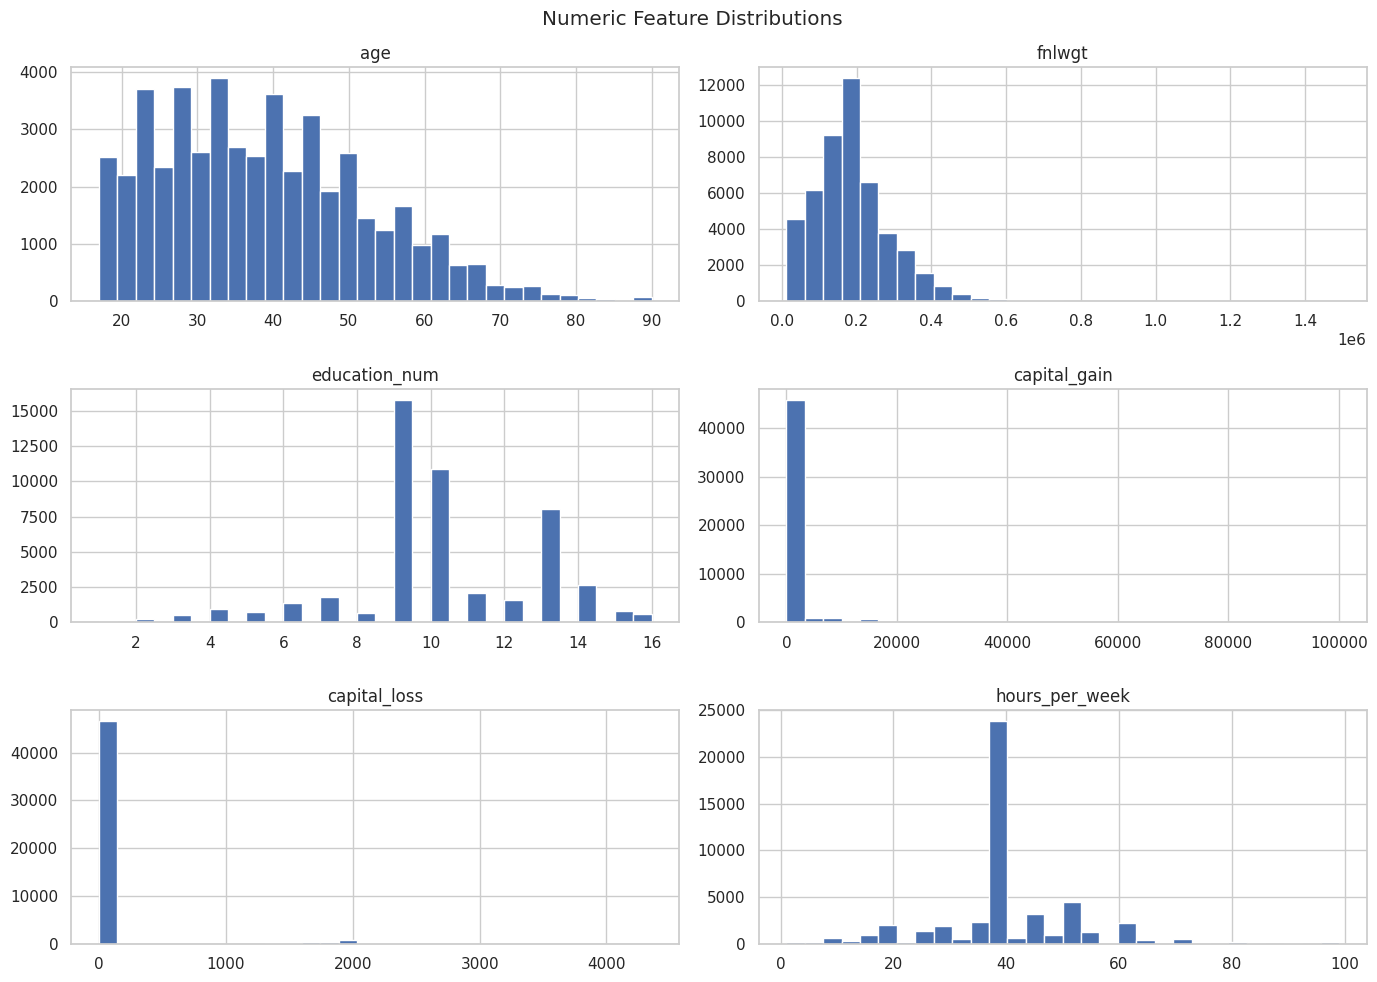

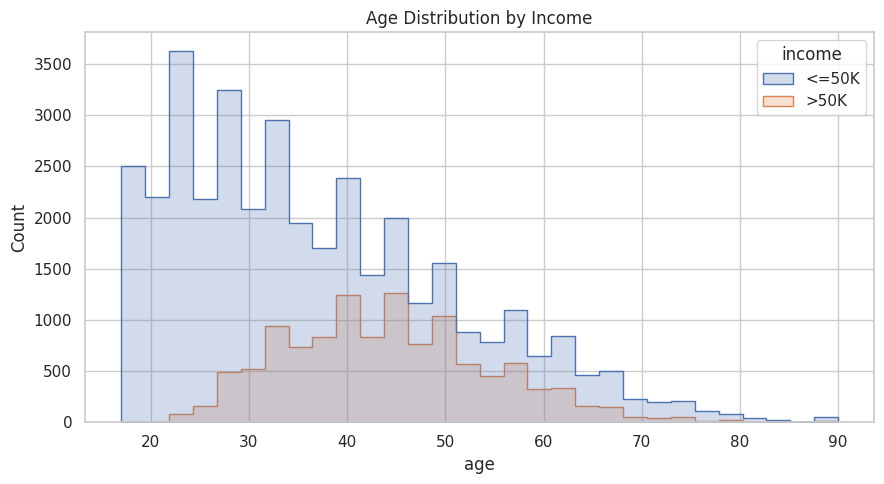

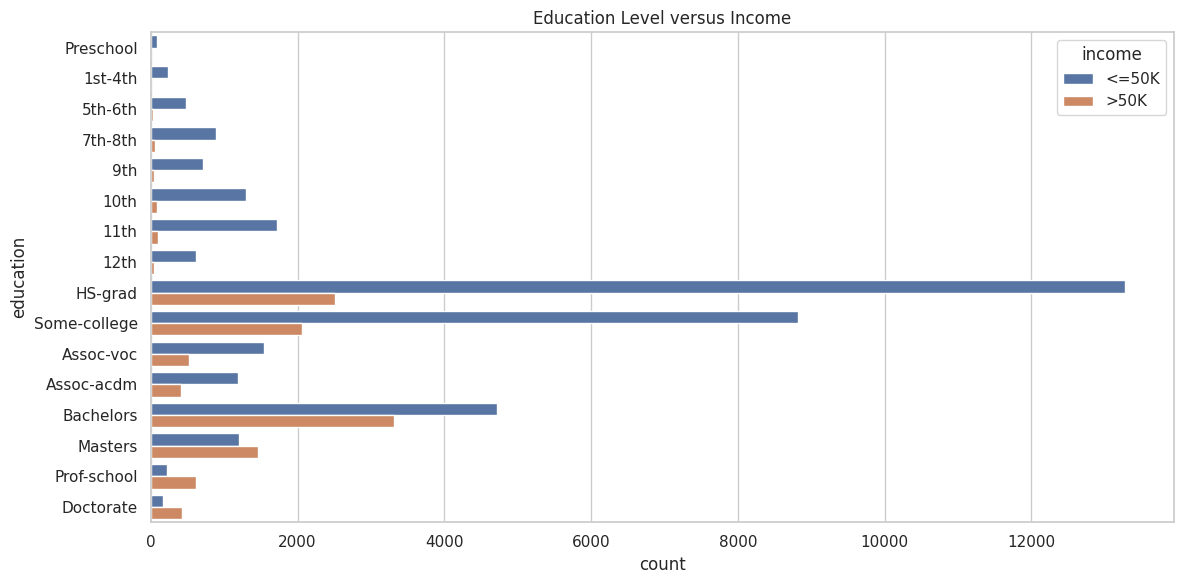


Percentage earning >50K by occupation:

occupation
Exec-managerial      47.78
Prof-specialty       45.11
Armed-Forces         33.33
Protective-serv      31.33
Tech-support         29.05
Sales                26.80
Craft-repair         22.63
Transport-moving     20.42
Adm-clerical         13.69
Machine-op-inspct    12.31
Farming-fishing      11.61
Handlers-cleaners     6.66
Other-service         4.14
Priv-house-serv       1.24
Name: income, dtype: float64


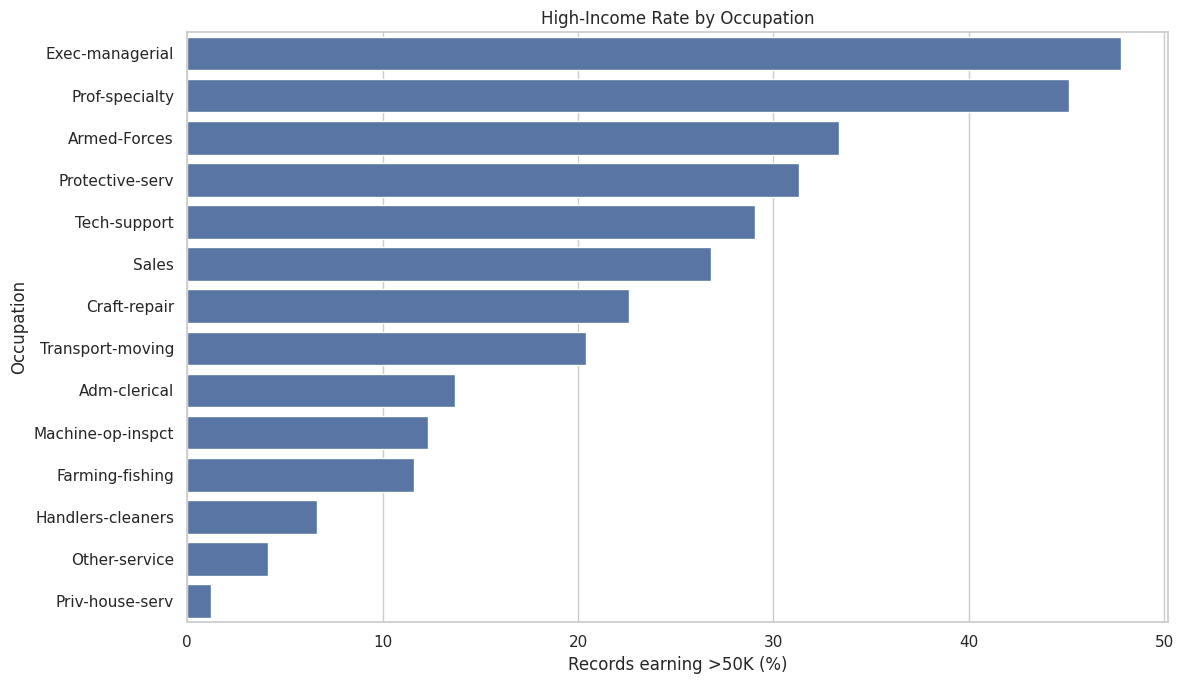

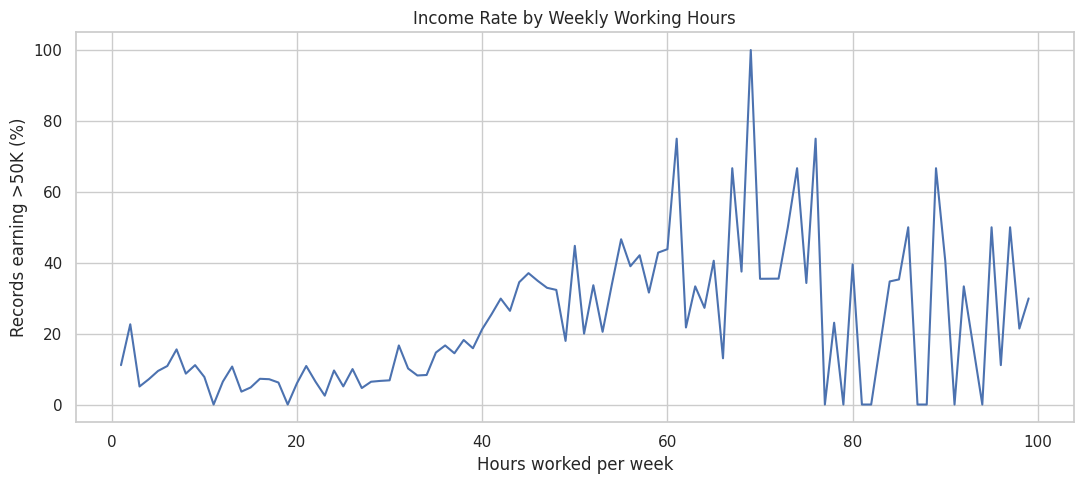


Numeric correlations:
                   age  fnlwgt  education_num  capital_gain  capital_loss  \
age             1.000  -0.077          0.031         0.077         0.057   
fnlwgt         -0.077   1.000         -0.039        -0.004        -0.004   
education_num   0.031  -0.039          1.000         0.125         0.081   
capital_gain    0.077  -0.004          0.125         1.000        -0.031   
capital_loss    0.057  -0.004          0.081        -0.031         1.000   
hours_per_week  0.072  -0.014          0.144         0.082         0.054   
income_binary   0.230  -0.006          0.333         0.223         0.148   

                hours_per_week  income_binary  
age                      0.072          0.230  
fnlwgt                  -0.014         -0.006  
education_num            0.144          0.333  
capital_gain             0.082          0.223  
capital_loss             0.054          0.148  
hours_per_week           1.000          0.228  
income_binary            0.228 

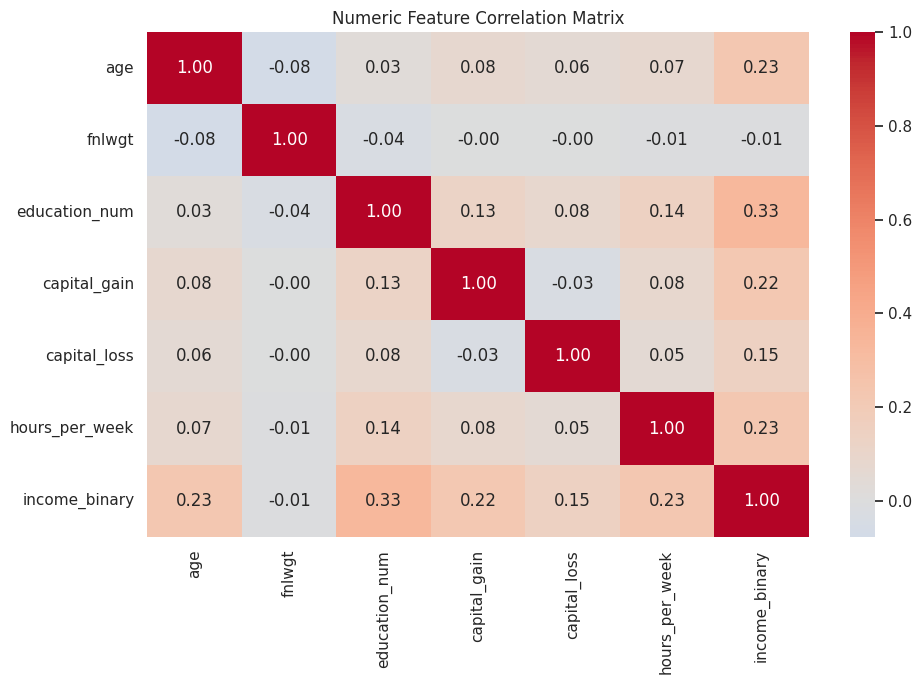


EDA completed.
Reports and charts saved in: /content/eda_outputs


In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Configuration
FILE = "adult_combined.csv"
OUTPUT_DIR = Path("eda_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")

# 1. Load dataset
df = pd.read_csv(FILE)
df.columns = df.columns.str.strip()

# Standardize text fields
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

df.replace("?", np.nan, inplace=True)

print("=" * 60)
print("1. DATASET OVERVIEW")
print("=" * 60)
print("Shape:", df.shape)
print("\nFirst 5 rows:\n", df.head())
print("\nData types:\n", df.dtypes)
print("\nUnique values per column:\n", df.nunique())

# 2. Data quality
print("\n" + "=" * 60)
print("2. DATA QUALITY")
print("=" * 60)
print("Duplicate rows:", df.duplicated().sum())

missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2)
}).sort_values("missing_percent", ascending=False)

print("\nMissing values:\n", missing)
missing.to_csv(OUTPUT_DIR / "missing_values.csv")

# 3. Descriptive statistics
print("\n" + "=" * 60)
print("3. STATISTICAL SUMMARY")
print("=" * 60)
print(df.describe(include="all").T)
df.describe(include="all").T.to_csv(
    OUTPUT_DIR / "descriptive_statistics.csv"
)

# 4. Target distribution
print("\n" + "=" * 60)
print("4. INCOME DISTRIBUTION")
print("=" * 60)
print(df["income"].value_counts())
print("\nPercentages:")
print((df["income"].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="income")
plt.title("Income Class Distribution")
plt.xlabel("Annual income")
plt.ylabel("Number of people")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_income_distribution.png", dpi=150)
plt.show()

# 5. Numeric distributions
numeric_cols = [
    "age", "fnlwgt", "education_num",
    "capital_gain", "capital_loss", "hours_per_week"
]

df[numeric_cols].hist(figsize=(14, 10), bins=30)
plt.suptitle("Numeric Feature Distributions")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_numeric_distributions.png", dpi=150)
plt.show()

# 6. Age versus income
plt.figure(figsize=(9, 5))
sns.histplot(
    data=df, x="age", hue="income",
    bins=30, element="step", stat="count",
    common_norm=False
)
plt.title("Age Distribution by Income")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_age_by_income.png", dpi=150)
plt.show()

# 7. Education versus income
education_order = (
    df.groupby("education")["education_num"]
    .median()
    .sort_values()
    .index
)

plt.figure(figsize=(12, 6))
sns.countplot(
    data=df, y="education", hue="income",
    order=education_order
)
plt.title("Education Level versus Income")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_education_by_income.png", dpi=150)
plt.show()

# 8. Occupation versus income
occupation_order = (
    df.groupby("occupation")["income"]
    .apply(lambda s: (s == ">50K").mean())
    .sort_values(ascending=False)
    .index
)

occupation_rates = (
    df.groupby("occupation")["income"]
    .apply(lambda s: (s == ">50K").mean() * 100)
    .sort_values(ascending=False)
)

print("\nPercentage earning >50K by occupation:\n")
print(occupation_rates.round(2))

plt.figure(figsize=(12, 7))
sns.barplot(
    x=occupation_rates.values,
    y=occupation_rates.index
)
plt.xlabel("Records earning >50K (%)")
plt.ylabel("Occupation")
plt.title("High-Income Rate by Occupation")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_occupation_income_rate.png", dpi=150)
plt.show()

# 9. Income rate by hours worked
hours_rate = (
    df.groupby("hours_per_week")["income"]
    .apply(lambda s: (s == ">50K").mean() * 100)
)

plt.figure(figsize=(11, 5))
hours_rate.plot()
plt.xlabel("Hours worked per week")
plt.ylabel("Records earning >50K (%)")
plt.title("Income Rate by Weekly Working Hours")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "06_hours_income_rate.png", dpi=150)
plt.show()

# 10. Correlation between numeric features
# Encode target only for exploratory correlation
df["income_binary"] = df["income"].map({
    "<=50K": 0,
    ">50K": 1
})

correlation = df[numeric_cols + ["income_binary"]].corr()

print("\nNumeric correlations:\n", correlation.round(3))
correlation.to_csv(OUTPUT_DIR / "correlation_matrix.csv")

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation, annot=True, fmt=".2f",
    cmap="coolwarm", center=0
)
plt.title("Numeric Feature Correlation Matrix")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "07_correlation_matrix.png", dpi=150)
plt.show()

# 11. Save cleaned analysis copy
df.drop(columns=["income_binary"]).to_csv(
    OUTPUT_DIR / "adult_eda_cleaned.csv", index=False
)

print("\nEDA completed.")
print("Reports and charts saved in:", OUTPUT_DIR.resolve())


In [ ]:
#=======================================
# Income Analysis by Age, Status , Edu
#======================================


INCOME RATE BY MARITAL_STATUS
       marital_status  total_people  high_income_people income_rate
   Married-civ-spouse         22379                9984      44.61%
    Married-AF-spouse            37                  14      37.84%
             Divorced          6633                 671      10.12%
Married-spouse-absent           628                  58       9.24%
              Widowed          1518                 128       8.43%
            Separated          1530                  99       6.47%
        Never-married         16117                 733       4.55%


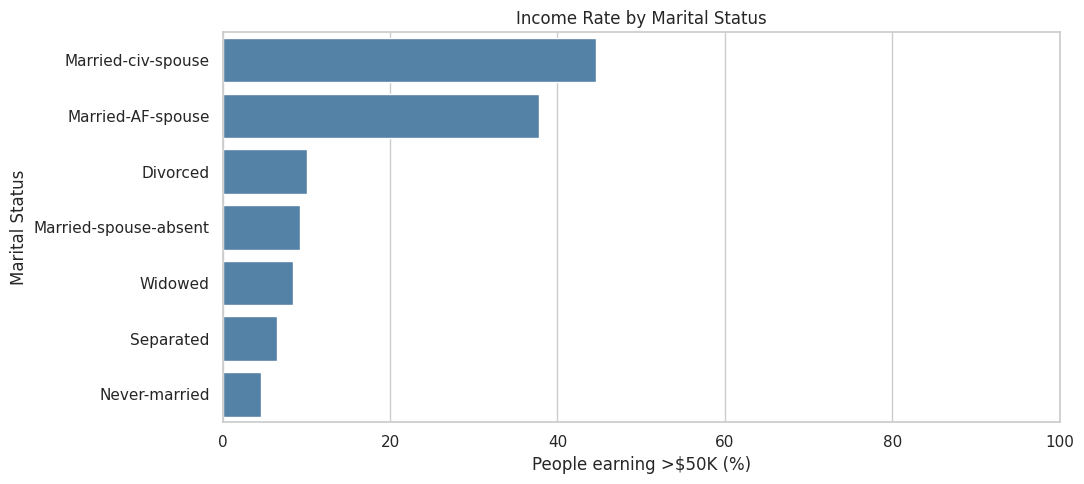


INCOME RATE BY EDUCATION
   education  total_people  high_income_people income_rate
 Prof-school           834                 617      73.98%
   Doctorate           594                 431      72.56%
     Masters          2657                1459      54.91%
   Bachelors          8025                3313      41.28%
  Assoc-acdm          1601                 413      25.80%
   Assoc-voc          2061                 522      25.33%
Some-college         10878                2063      18.96%
     HS-grad         15784                2503      15.86%
        12th           657                  48       7.31%
     7th-8th           955                  62       6.49%
        10th          1389                  87       6.26%
         9th           756                  41       5.42%
     5th-6th           509                  27       5.30%
        11th          1812                  92       5.08%
     1st-4th           247                   8       3.24%
   Preschool            83    

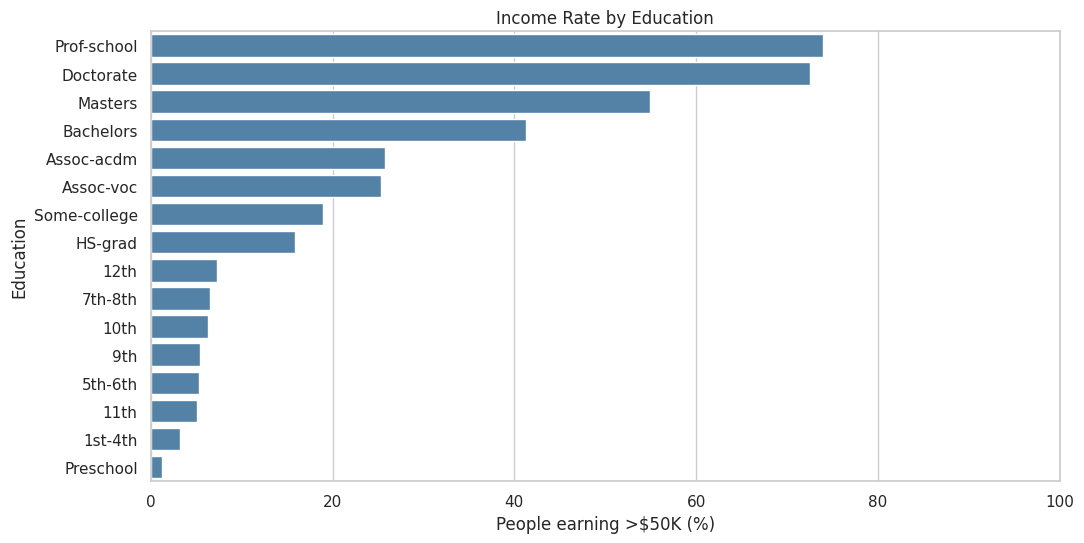


INCOME RATE BY WORKCLASS
       workclass  total_people  high_income_people income_rate
    Self-emp-inc          1695                 938      55.34%
     Federal-gov          1432                 561      39.18%
       Local-gov          3136                 927      29.56%
Self-emp-not-inc          3862                1077      27.89%
       State-gov          1981                 530      26.75%
         Private         33906                7387      21.79%
     Without-pay            21                   2       9.52%
             NaN          2799                 265       9.47%
    Never-worked            10                   0       0.00%


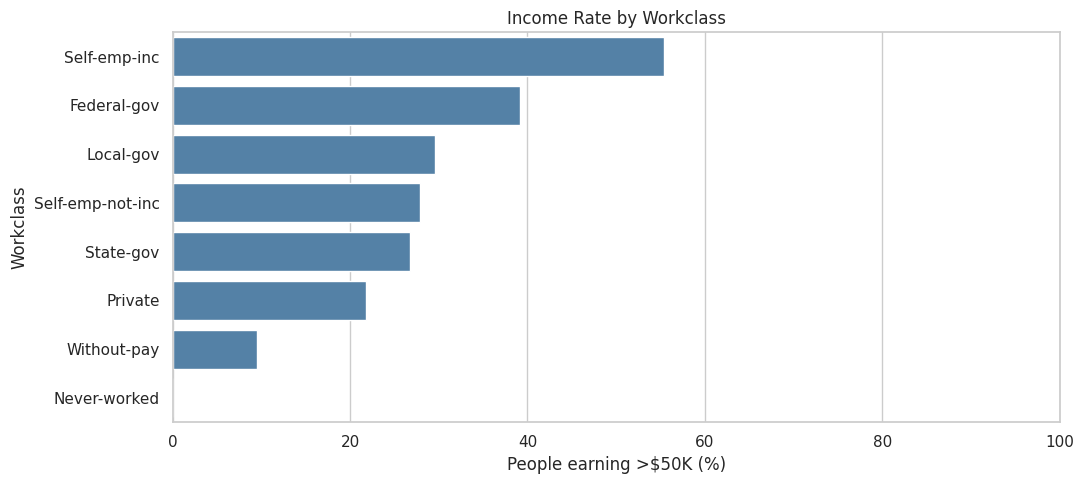


INCOME RATE BY SEX
   sex  total_people  high_income_people income_rate
  Male         32650                9918      30.38%
Female         16192                1769      10.93%


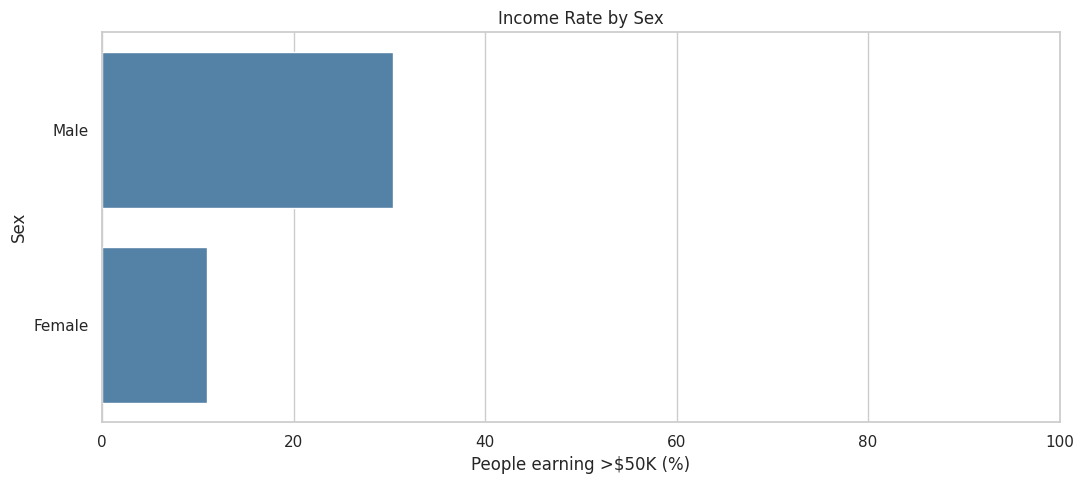


INCOME RATE BY RACE
              race  total_people  high_income_people income_rate
Asian-Pac-Islander          1519                 409      26.93%
             White         41762               10607      25.40%
             Other           406                  50      12.32%
             Black          4685                 566      12.08%
Amer-Indian-Eskimo           470                  55      11.70%


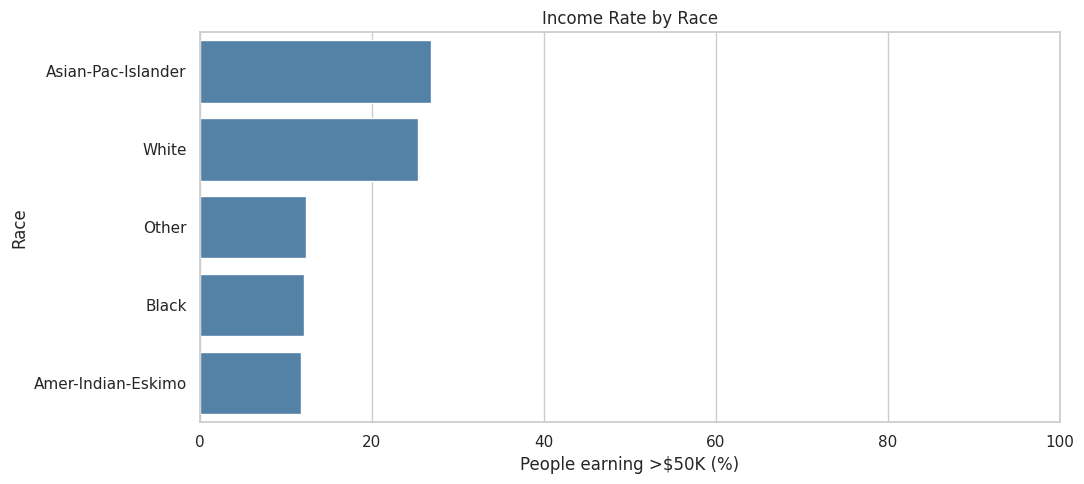


INCOME RATE BY RELATIONSHIP
  relationship  total_people  high_income_people income_rate
          Wife          2331                1093      46.89%
       Husband         19716                8846      44.87%
 Not-in-family         12583                1276      10.14%
     Unmarried          5125                 309       6.03%
Other-relative          1506                  52       3.45%
     Own-child          7581                 111       1.46%


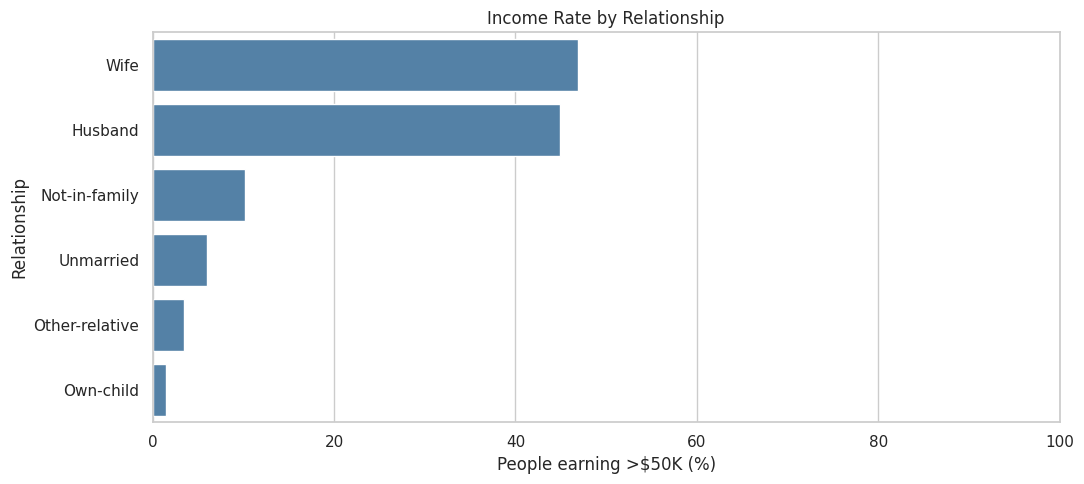


INCOME RATE BY OCCUPATION
       occupation  total_people  high_income_people income_rate
  Exec-managerial          6086                2908      47.78%
   Prof-specialty          6172                2784      45.11%
     Armed-Forces            15                   5      33.33%
  Protective-serv           983                 308      31.33%
     Tech-support          1446                 420      29.05%
            Sales          5504                1475      26.80%
     Craft-repair          6112                1383      22.63%
 Transport-moving          2355                 481      20.42%
     Adm-clerical          5611                 768      13.69%
Machine-op-inspct          3022                 372      12.31%
  Farming-fishing          1490                 173      11.61%
              NaN          2809                 265       9.43%
Handlers-cleaners          2072                 138       6.66%
    Other-service          4923                 204       4.14%
  Priv-house-

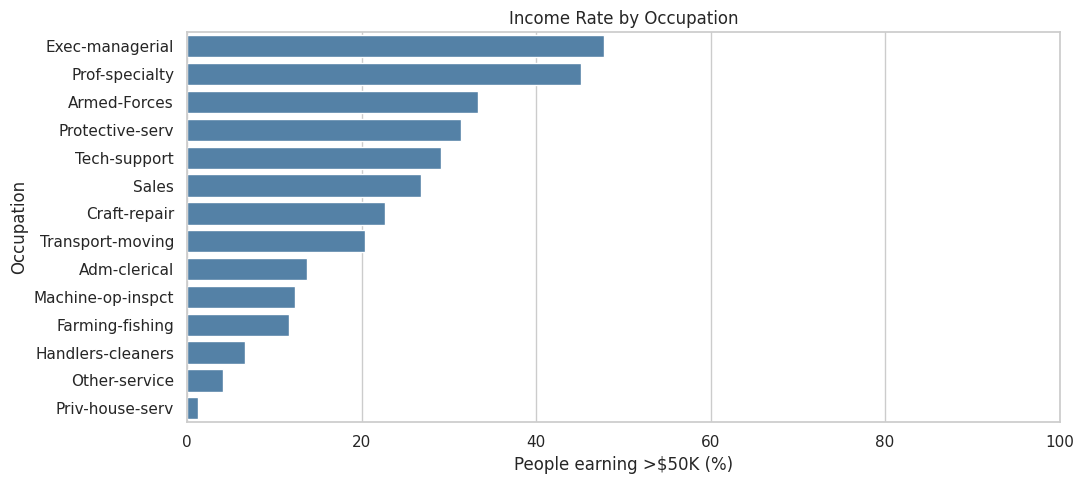


INCOME RATE BY NATIVE_COUNTRY
    native_country  total_people  high_income_people income_rate
             India           151                  62      41.06%
           England           127                  47      37.01%
            Canada           182                  63      34.62%
             Italy           105                  34      32.38%
             China           122                  36      29.51%
       Philippines           295                  85      28.81%
           Germany           206                  58      28.16%
               NaN           857                 220      25.67%
              Cuba           138                  34      24.64%
     United-States         43832               10694      24.40%
             South           115                  20      17.39%
           Jamaica           106                  15      14.15%
       Puerto-Rico           184                  20      10.87%
       El-Salvador           155                  11       

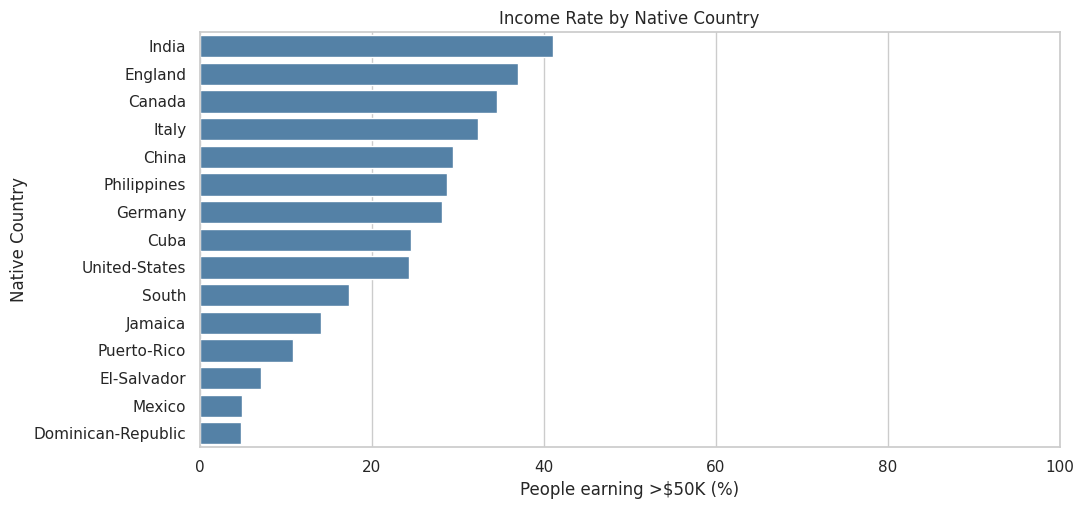

/tmp/ipykernel_807/1185302870.py:33: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(column, dropna=False)



INCOME RATE BY AGE_GROUP
age_group  total_people  high_income_people income_rate
    45-54          8771                3455      39.39%
    35-44         12193                4059      33.29%
    55-64          4782                1538      32.16%
      65+          2087                 427      20.46%
    25-34         12577                2115      16.82%
    17-24          8432                  93       1.10%


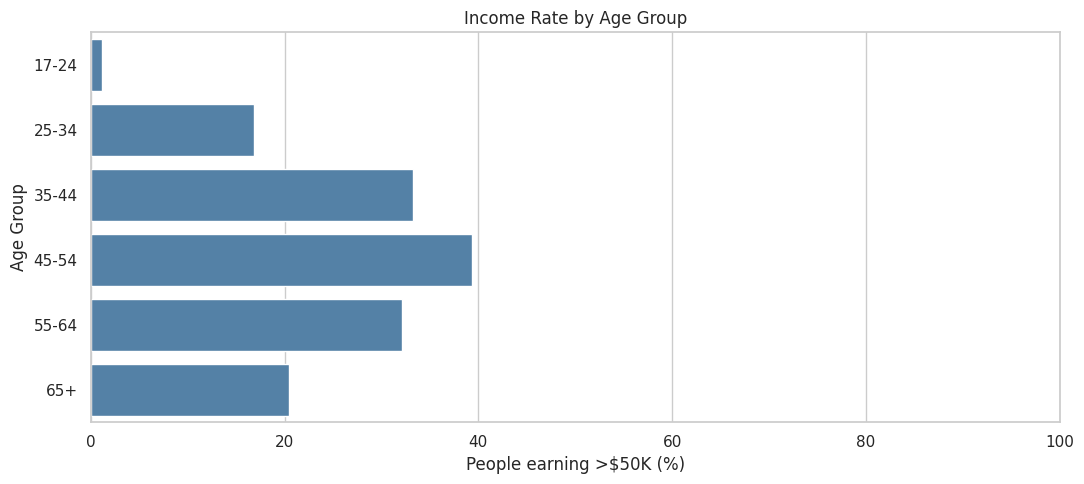

/tmp/ipykernel_807/1185302870.py:33: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(column, dropna=False)



INCOME RATE BY HOURS_GROUP
hours_group  total_people  high_income_people income_rate
      50-59          5828                2571      44.11%
      60-99          3853                1553      40.31%
      40-49         27474                6468      23.54%
      35-39          3292                 515      15.64%
       1-19          2591                 189       7.29%
      20-34          5804                 391       6.74%


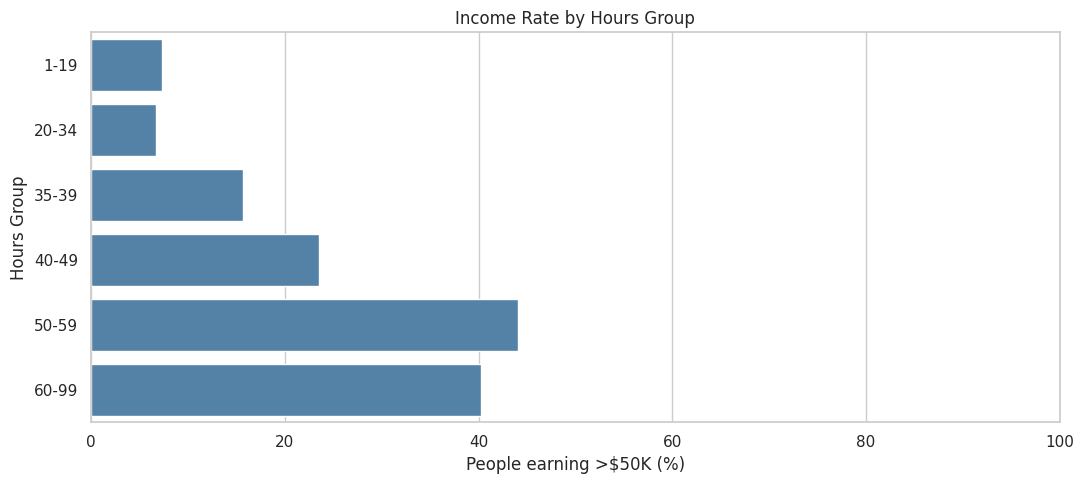


INCOME RATE BY EDUCATION_NUM
 education_num  total_people  high_income_people income_rate
            15           834                 617      73.98%
            16           594                 431      72.56%
            14          2657                1459      54.91%
            13          8025                3313      41.28%
            12          1601                 413      25.80%
            11          2061                 522      25.33%
            10         10878                2063      18.96%
             9         15784                2503      15.86%
             8           657                  48       7.31%
             4           955                  62       6.49%
             6          1389                  87       6.26%
             5           756                  41       5.42%
             3           509                  27       5.30%
             7          1812                  92       5.08%
             2           247                   8       

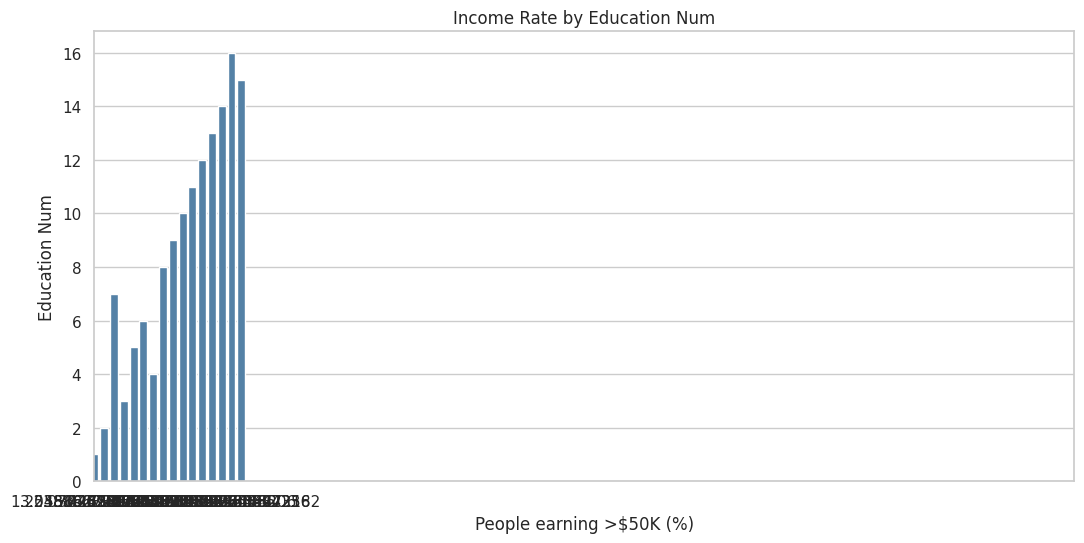


INCOME RATE BY MARITAL STATUS AND SEX
       marital_status    sex  total_people  high_income_people  income_rate
             Divorced Female          4001                 274     6.848288
             Divorced   Male          2632                 397    15.083587
    Married-AF-spouse Female            25                  10    40.000000
    Married-AF-spouse   Male            12                   4    33.333333
   Married-civ-spouse Female          2480                1111    44.798387
   Married-civ-spouse   Male         19899                8873    44.590180
Married-spouse-absent Female           304                  18     5.921053
Married-spouse-absent   Male           324                  40    12.345679
        Never-married Female          7218                 259     3.588252
        Never-married   Male          8899                 474     5.326441
            Separated Female           931                  28     3.007519
            Separated   Male           599       

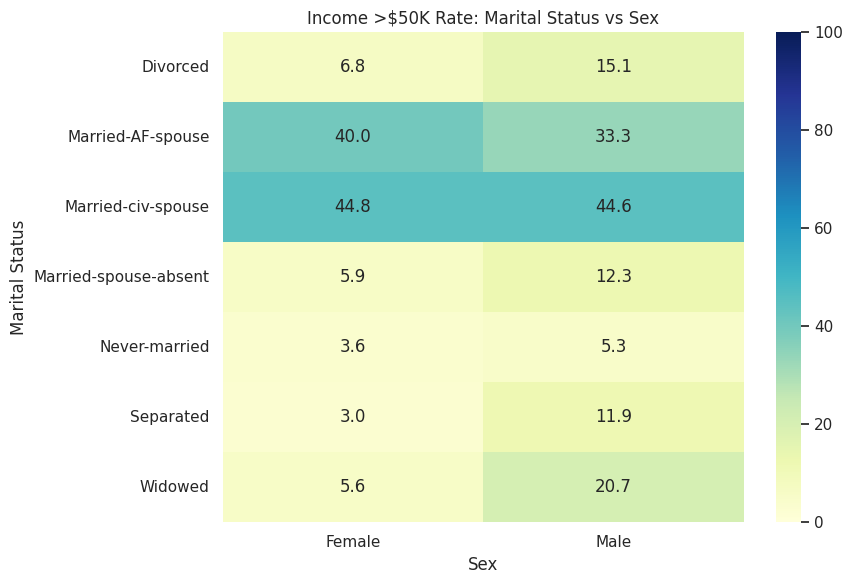


OVERALL INCOME SUMMARY
Total records: 48842
Income >$50K: 11687
Income <=$50K: 37155
Overall >$50K rate: 23.93%

All reports and charts saved to:
/content/income_rate_outputs


In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# --------------------------------------------------
# 1. LOAD DATA
# --------------------------------------------------
FILE = "adult_combined.csv"
OUTPUT_DIR = Path("income_rate_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")

df = pd.read_csv(FILE, skipinitialspace=True)

# Clean whitespace and missing-value markers
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

df.replace("?", np.nan, inplace=True)
df["income"] = df["income"].str.rstrip(".")

# Binary target: 1 = income >50K, 0 = income <=50K
df["high_income"] = (df["income"] == ">50K").astype(int)

# --------------------------------------------------
# 2. REUSABLE INCOME RATE FUNCTION
# --------------------------------------------------
def income_rate(column, min_count=1):
    result = (
        df.groupby(column, dropna=False)
        .agg(
            total_people=("high_income", "size"),
            high_income_people=("high_income", "sum"),
            income_rate=("high_income", "mean")
        )
        .reset_index()
    )

    result["income_rate"] *= 100
    result = result[result["total_people"] >= min_count]

    return result.sort_values("income_rate", ascending=False)


def analyze_category(column, min_count=1):
    result = income_rate(column, min_count)

    print("\n" + "=" * 70)
    print(f"INCOME RATE BY {column.upper()}")
    print("=" * 70)

    print(
        result.to_string(
            index=False,
            formatters={"income_rate": "{:.2f}%".format}
        )
    )

    result.to_csv(
        OUTPUT_DIR / f"income_rate_by_{column}.csv",
        index=False
    )

    # Plot percentage earning above $50K
    plot_data = result.dropna(subset=[column])

    plt.figure(figsize=(11, max(5, len(plot_data) * 0.35)))
    sns.barplot(
        data=plot_data,
        x="income_rate",
        y=column,
        color="steelblue"
    )
    plt.xlabel("People earning >$50K (%)")
    plt.ylabel(column.replace("_", " ").title())
    plt.title(f"Income Rate by {column.replace('_', ' ').title()}")
    plt.xlim(0, 100)
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / f"income_rate_by_{column}.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()


# --------------------------------------------------
# 3. CATEGORICAL FEATURES
# --------------------------------------------------
categorical_features = [
    "marital_status",
    "education",
    "workclass",
    "sex",
    "race",
    "relationship",
    "occupation",
    "native_country"
]

for col in categorical_features:
    analyze_category(col, min_count=100 if col == "native_country" else 1)


# --------------------------------------------------
# 4. AGE GROUP ANALYSIS
# --------------------------------------------------
df["age_group"] = pd.cut(
    df["age"],
    bins=[16, 25, 35, 45, 55, 65, 100],
    labels=[
        "17-24", "25-34", "35-44",
        "45-54", "55-64", "65+"
    ],
    right=False
)

analyze_category("age_group")


# --------------------------------------------------
# 5. WEEKLY WORKING HOURS
# --------------------------------------------------
df["hours_group"] = pd.cut(
    df["hours_per_week"],
    bins=[0, 20, 35, 40, 50, 60, 100],
    labels=[
        "1-19", "20-34", "35-39",
        "40-49", "50-59", "60-99"
    ],
    right=False
)

analyze_category("hours_group")


# --------------------------------------------------
# 6. EDUCATION NUMERIC LEVEL
# --------------------------------------------------
analyze_category("education_num")


# --------------------------------------------------
# 7. COMBINED ANALYSIS:
# MARITAL STATUS VS SEX
# --------------------------------------------------
marital_sex = (
    df.groupby(["marital_status", "sex"], dropna=False)
    .agg(
        total_people=("high_income", "size"),
        high_income_people=("high_income", "sum"),
        income_rate=("high_income", "mean")
    )
    .reset_index()
)

marital_sex["income_rate"] *= 100

marital_sex.to_csv(
    OUTPUT_DIR / "income_rate_marital_status_and_sex.csv",
    index=False
)

print("\n" + "=" * 70)
print("INCOME RATE BY MARITAL STATUS AND SEX")
print("=" * 70)
print(marital_sex.to_string(index=False))

# Pivot table for heatmap
pivot = marital_sex.pivot(
    index="marital_status",
    columns="sex",
    values="income_rate"
)

plt.figure(figsize=(9, 6))
sns.heatmap(
    pivot,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    vmin=0,
    vmax=100
)
plt.title("Income >$50K Rate: Marital Status vs Sex")
plt.xlabel("Sex")
plt.ylabel("Marital Status")
plt.tight_layout()
plt.savefig(
    OUTPUT_DIR / "marital_status_vs_sex_heatmap.png",
    dpi=150
)
plt.show()


# --------------------------------------------------
# 8. FINAL SUMMARY
# --------------------------------------------------
print("\n" + "=" * 70)
print("OVERALL INCOME SUMMARY")
print("=" * 70)

print("Total records:", len(df))
print("Income >$50K:", int(df["high_income"].sum()))
print("Income <=$50K:", int((df["high_income"] == 0).sum()))
print(f"Overall >$50K rate: {df['high_income'].mean() * 100:.2f}%")

print("\nAll reports and charts saved to:")
print(OUTPUT_DIR.resolve())


In [ ]:
#============================
# Numeric Featuers Analysis
#============================


========== NUMERIC SUMMARY ==========
                  count       mean        std      min       25%       50%       75%        max    median  skewness  zero_count  zero_percentage
age             48842.0      38.64      13.71     17.0      28.0      37.0      48.0       90.0      37.0      0.56           0             0.00
fnlwgt          48842.0  189664.13  105604.03  12285.0  117550.5  178144.5  237642.0  1490400.0  178144.5      1.44           0             0.00
education_num   48842.0      10.08       2.57      1.0       9.0      10.0      12.0       16.0      10.0     -0.32           0             0.00
capital_gain    48842.0    1079.07    7452.02      0.0       0.0       0.0       0.0    99999.0       0.0     11.89       44807            91.74
capital_loss    48842.0      87.50     403.00      0.0       0.0       0.0       0.0     4356.0       0.0      4.57       46560            95.33
hours_per_week  48842.0      40.42      12.39      1.0      40.0      40.0      45.0       

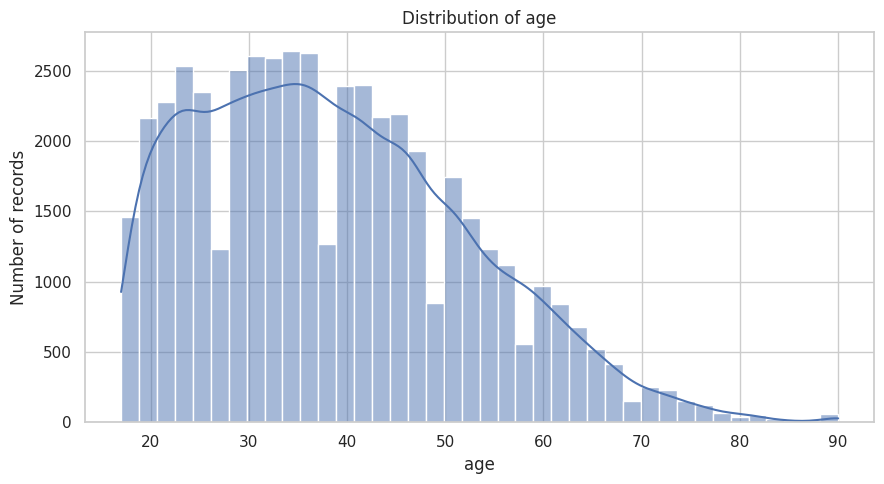

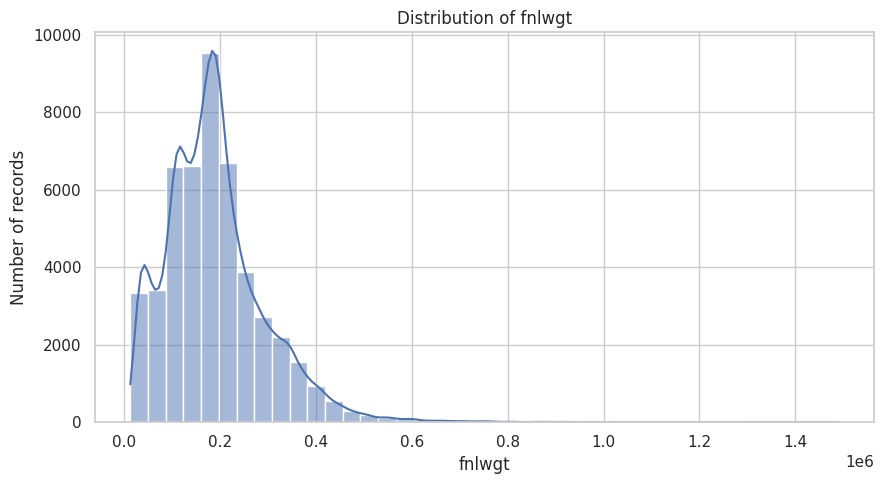

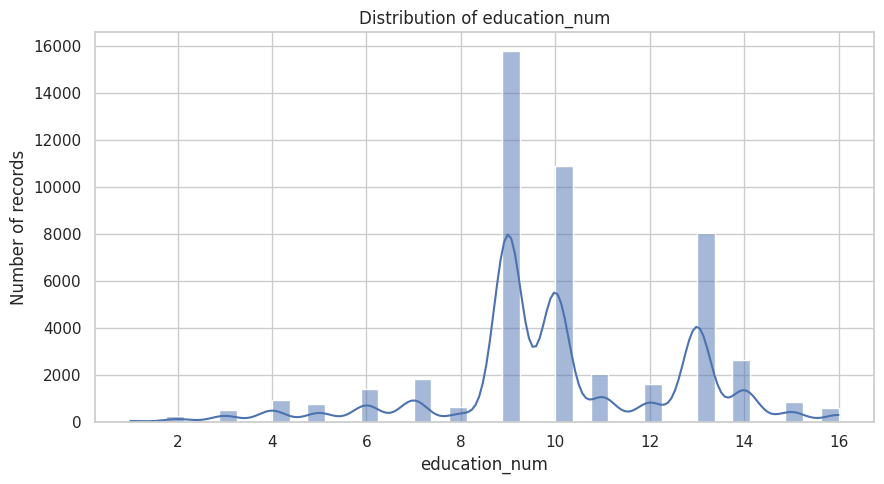

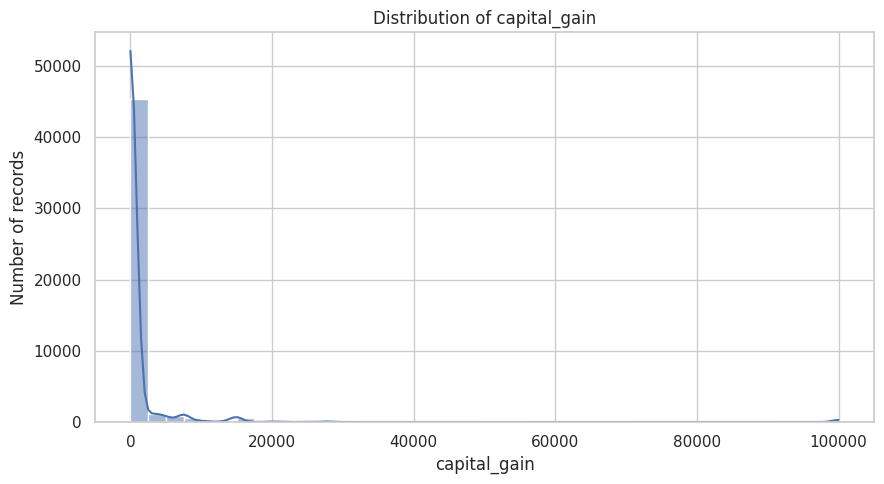

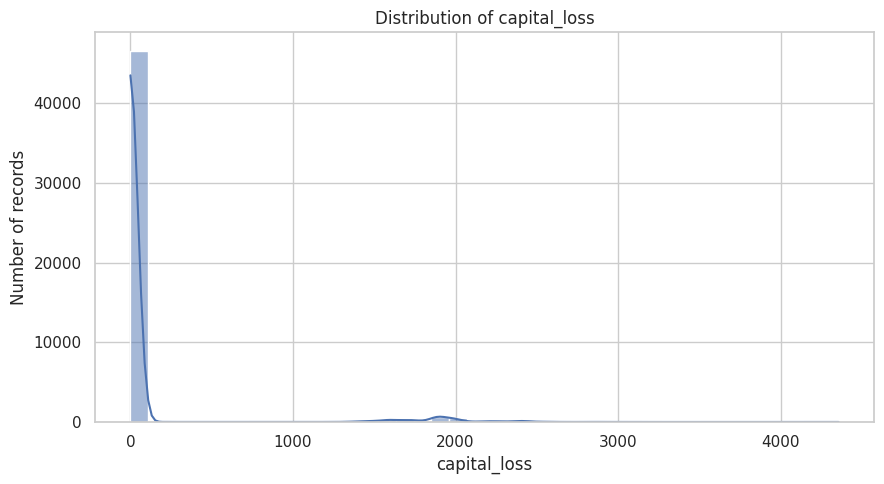

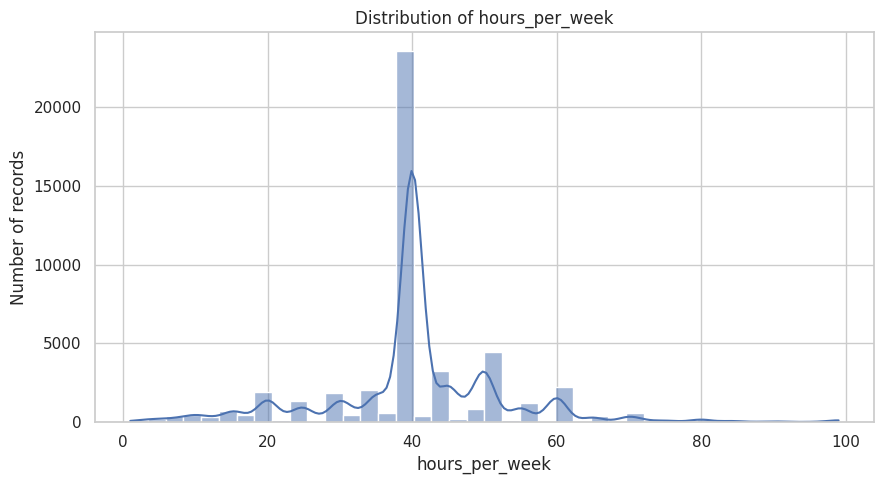

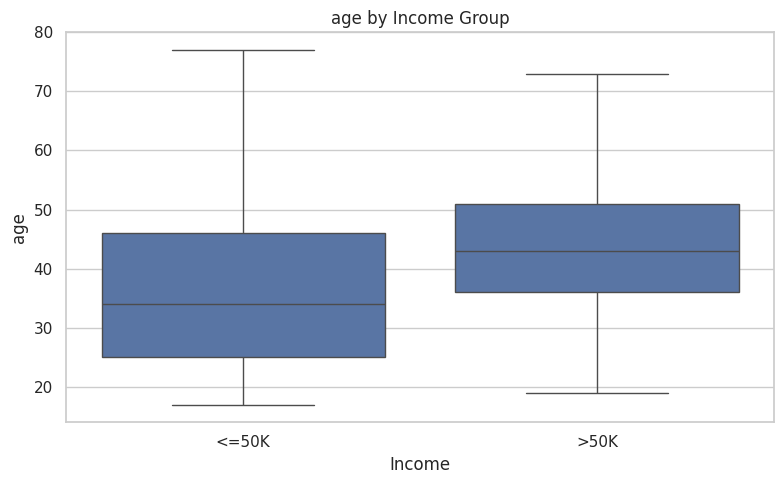

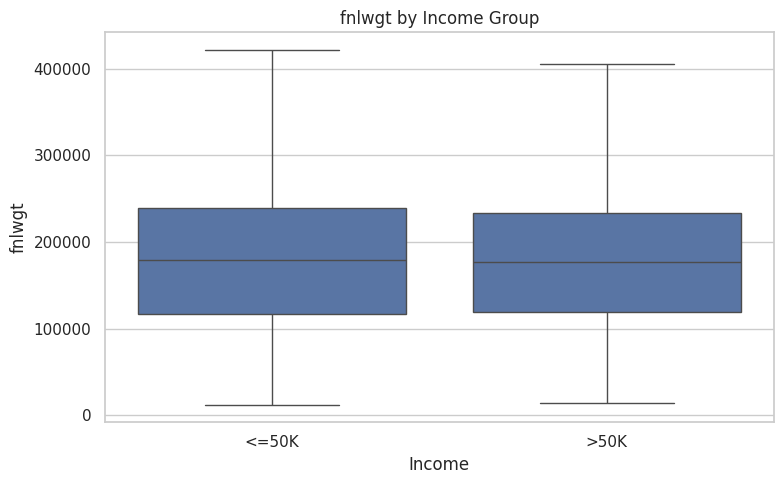

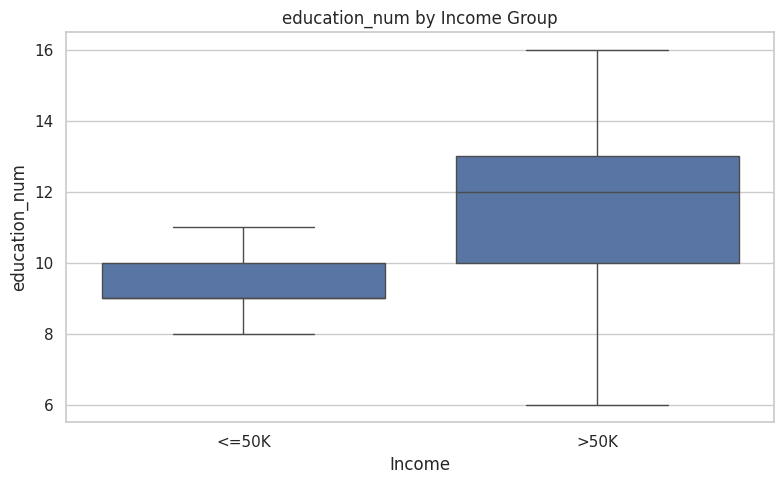

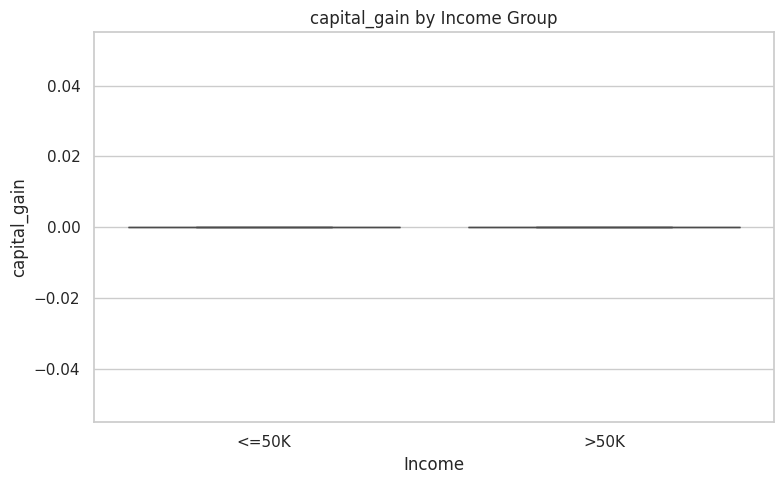

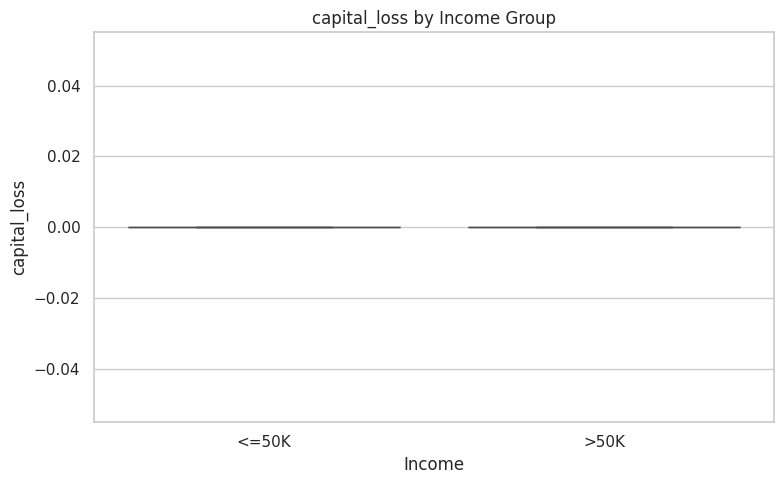

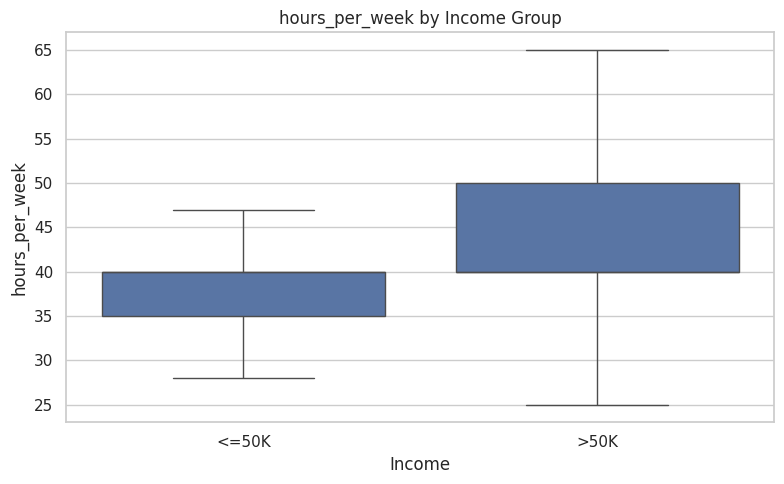


========== NUMERIC FEATURES BY INCOME ==========
          age                   fnlwgt                      education_num              capital_gain                  capital_loss                hours_per_week              
         mean median    std       mean    median        std          mean median   std         mean median       std         mean median     std           mean median    std
income                                                                                                                                                                       
<=50K   36.87   34.0  14.10  190039.57  178811.0  106577.60           9.6    9.0  2.44       147.01    0.0    936.75        54.15    0.0  313.32          38.84   40.0  12.36
>50K    44.28   43.0  10.56  188470.57  176729.0  102442.73          11.6   12.0  2.38      4042.24    0.0  14756.77       193.53    0.0  593.21          45.45   40.0  11.09

========== CAPITAL GAIN / LOSS ANALYSIS ==========

capital_gain
        total 

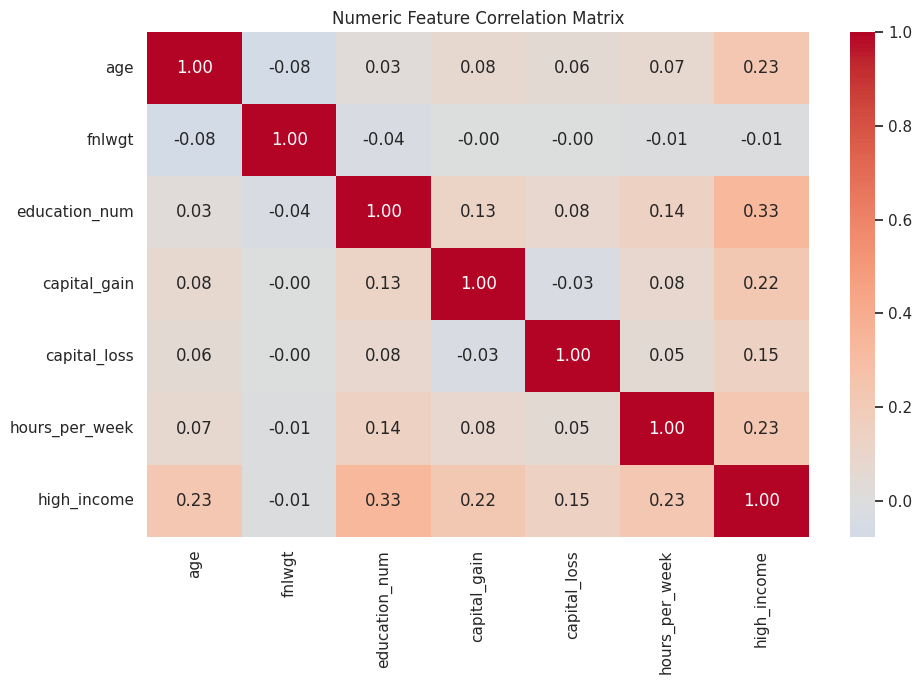


========== INCOME RATE BY AGE_GROUP ==========
age_group  count  sum  mean  income_rate_pct
    17-24   8432   93  0.01             1.10
    25-34  12577 2115  0.17            16.82
    35-44  12193 4059  0.33            33.29
    45-54   8771 3455  0.39            39.39
    55-64   4782 1538  0.32            32.16
      65+   2087  427  0.20            20.46

========== INCOME RATE BY HOURS_GROUP ==========
hours_group  count  sum  mean  income_rate_pct
       1-19   2591  189  0.07             7.29
      20-34   5804  391  0.07             6.74
      35-39   3292  515  0.16            15.64
      40-49  27474 6468  0.24            23.54
      50-59   5828 2571  0.44            44.11
      60-99   3853 1553  0.40            40.31

Numeric EDA completed.
Results saved to: /content/numeric_eda_outputs


In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# ==================================================
# 1. LOAD DATA
# ==================================================
df = pd.read_csv("adult_combined.csv", skipinitialspace=True)

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

df.replace("?", np.nan, inplace=True)
df["income"] = df["income"].str.rstrip(".")

output_dir = Path("numeric_eda_outputs")
output_dir.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")

numeric_features = [
    "age",
    "fnlwgt",
    "education_num",
    "capital_gain",
    "capital_loss",
    "hours_per_week"
]

# ==================================================
# 2. NUMERIC SUMMARY STATISTICS
# ==================================================
print("\n========== NUMERIC SUMMARY ==========")

summary = df[numeric_features].describe().T
summary["median"] = df[numeric_features].median()
summary["skewness"] = df[numeric_features].skew()
summary["zero_count"] = (df[numeric_features] == 0).sum()
summary["zero_percentage"] = (
    summary["zero_count"] / len(df) * 100
)

print(summary.round(2).to_string())
summary.to_csv(output_dir / "numeric_summary.csv")

# ==================================================
# 3. DISTRIBUTIONS: HISTOGRAMS
# ==================================================
for col in numeric_features:
    plt.figure(figsize=(9, 5))

    sns.histplot(
        data=df,
        x=col,
        bins=40,
        kde=(df[col].nunique() > 10)
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Number of records")
    plt.tight_layout()
    plt.savefig(output_dir / f"distribution_{col}.png", dpi=150)
    plt.show()
    plt.close()

# ==================================================
# 4. COMPARE NUMERIC FEATURES BY INCOME
# ==================================================
for col in numeric_features:
    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x="income",
        y=col,
        showfliers=False
    )

    plt.title(f"{col} by Income Group")
    plt.xlabel("Income")
    plt.ylabel(col)
    plt.tight_layout()
    plt.savefig(output_dir / f"boxplot_{col}_by_income.png", dpi=150)
    plt.show()
    plt.close()

# ==================================================
# 5. GROUP STATISTICS BY INCOME
# ==================================================
print("\n========== NUMERIC FEATURES BY INCOME ==========")

group_summary = df.groupby("income")[numeric_features].agg(
    ["mean", "median", "std"]
)

print(group_summary.round(2).to_string())
group_summary.to_csv(output_dir / "numeric_by_income.csv")

# ==================================================
# 6. ZERO VALUES IN CAPITAL GAIN / LOSS
# ==================================================
print("\n========== CAPITAL GAIN / LOSS ANALYSIS ==========")

for col in ["capital_gain", "capital_loss"]:
    print(f"\n{col}")

    zero_stats = df.groupby("income")[col].agg(
        total="count",
        zero_count=lambda s: (s == 0).sum(),
        mean="mean",
        median="median"
    )

    zero_stats["zero_percentage"] = (
        zero_stats["zero_count"] / zero_stats["total"] * 100
    )

    print(zero_stats.round(2).to_string())

    # Compare zero vs nonzero values
    df[f"{col}_status"] = np.where(
        df[col] == 0,
        "Zero",
        "Non-zero"
    )

    rate_table = pd.crosstab(
        df[f"{col}_status"],
        df["income"],
        normalize="index"
    ) * 100

    print("\nIncome distribution by value status (%):")
    print(rate_table.round(2).to_string())

    rate_table.to_csv(
        output_dir / f"{col}_income_by_zero_status.csv"
    )

# ==================================================
# 7. OUTLIER CHECK USING IQR
# ==================================================
print("\n========== IQR OUTLIER CHECK ==========")

outlier_rows = []

for col in numeric_features:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_rows.append({
        "feature": col,
        "lower_bound": lower,
        "upper_bound": upper,
        "outlier_count": int(count),
        "outlier_percentage": count / len(df) * 100
    })

outliers = pd.DataFrame(outlier_rows)
print(outliers.round(2).to_string(index=False))
outliers.to_csv(output_dir / "iqr_outlier_summary.csv", index=False)

# ==================================================
# 8. CORRELATION MATRIX
# ==================================================
df["high_income"] = (df["income"] == ">50K").astype(int)

corr = df[numeric_features + ["high_income"]].corr()

print("\n========== CORRELATION WITH HIGH INCOME ==========")
print(
    corr["high_income"]
    .drop("high_income")
    .sort_values(ascending=False)
    .round(3)
)

plt.figure(figsize=(10, 7))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Numeric Feature Correlation Matrix")
plt.tight_layout()
plt.savefig(output_dir / "correlation_matrix.png", dpi=150)
plt.show()
plt.close()

# ==================================================
# 9. AGE AND HOURS VS INCOME RATE
# ==================================================
df["age_group"] = pd.cut(
    df["age"],
    bins=[16, 25, 35, 45, 55, 65, 100],
    labels=["17-24", "25-34", "35-44", "45-54", "55-64", "65+"],
    right=False
)

df["hours_group"] = pd.cut(
    df["hours_per_week"],
    bins=[0, 20, 35, 40, 50, 60, 100],
    labels=["1-19", "20-34", "35-39", "40-49", "50-59", "60-99"],
    right=False
)

for col in ["age_group", "hours_group"]:
    rate = (
        df.groupby(col, observed=False)["high_income"]
        .agg(["count", "sum", "mean"])
        .reset_index()
    )

    rate["income_rate_pct"] = rate["mean"] * 100

    print(f"\n========== INCOME RATE BY {col.upper()} ==========")
    print(rate.round(2).to_string(index=False))
    rate.to_csv(output_dir / f"income_rate_{col}.csv", index=False)

# ==================================================
# 10. FINISH
# ==================================================
print("\nNumeric EDA completed.")
print("Results saved to:", output_dir.resolve())


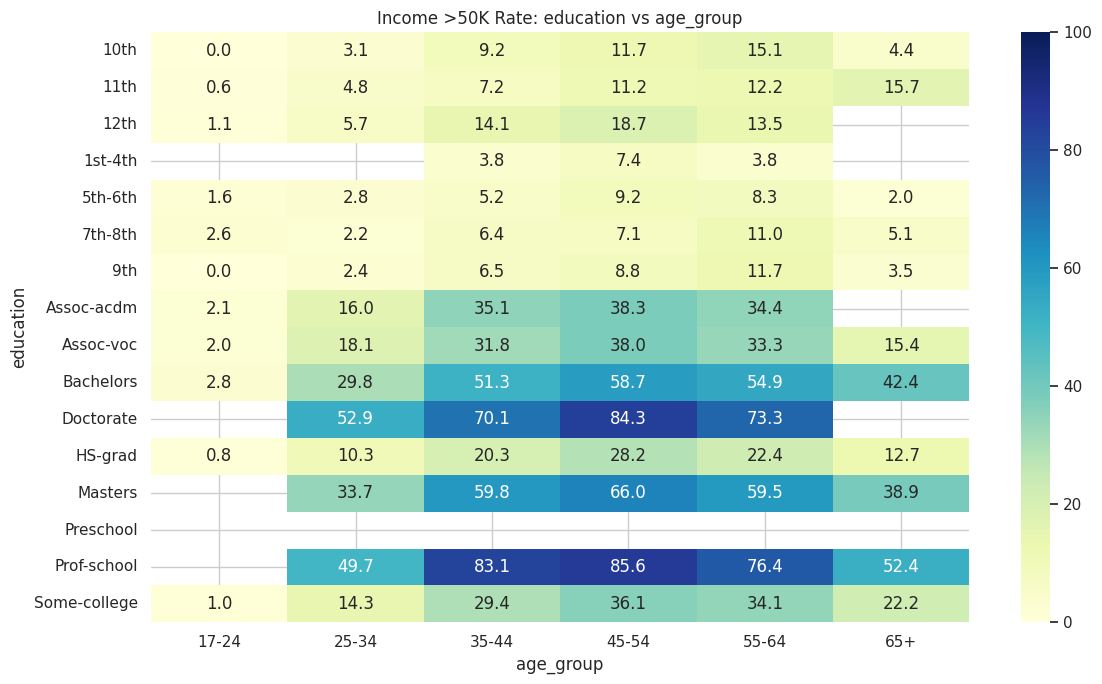

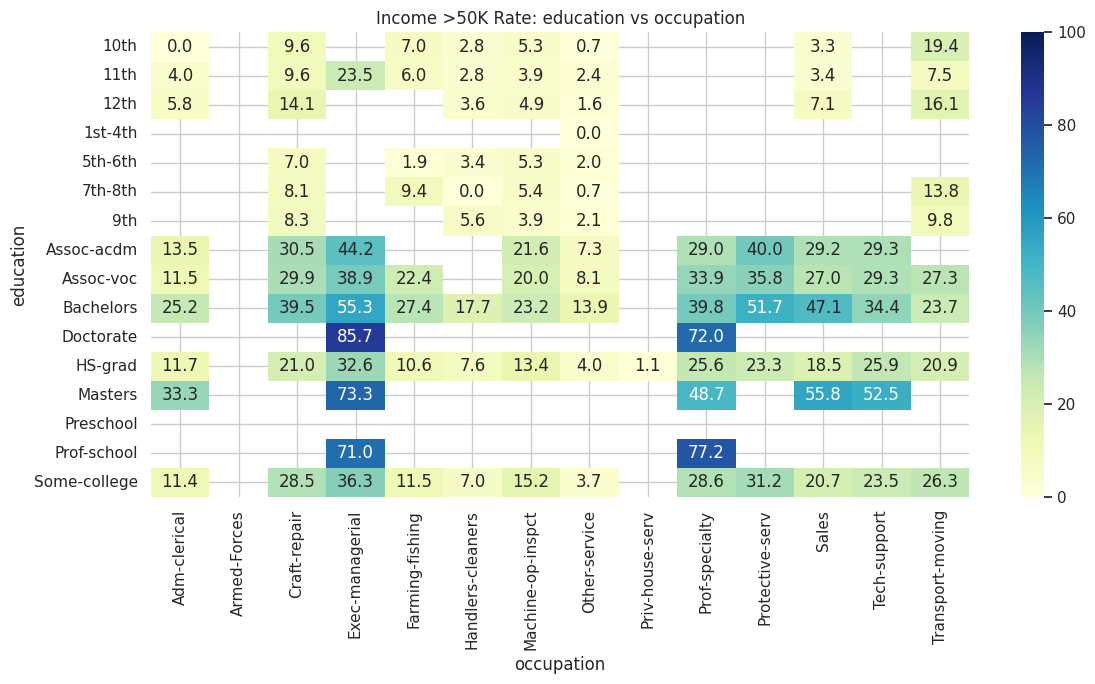

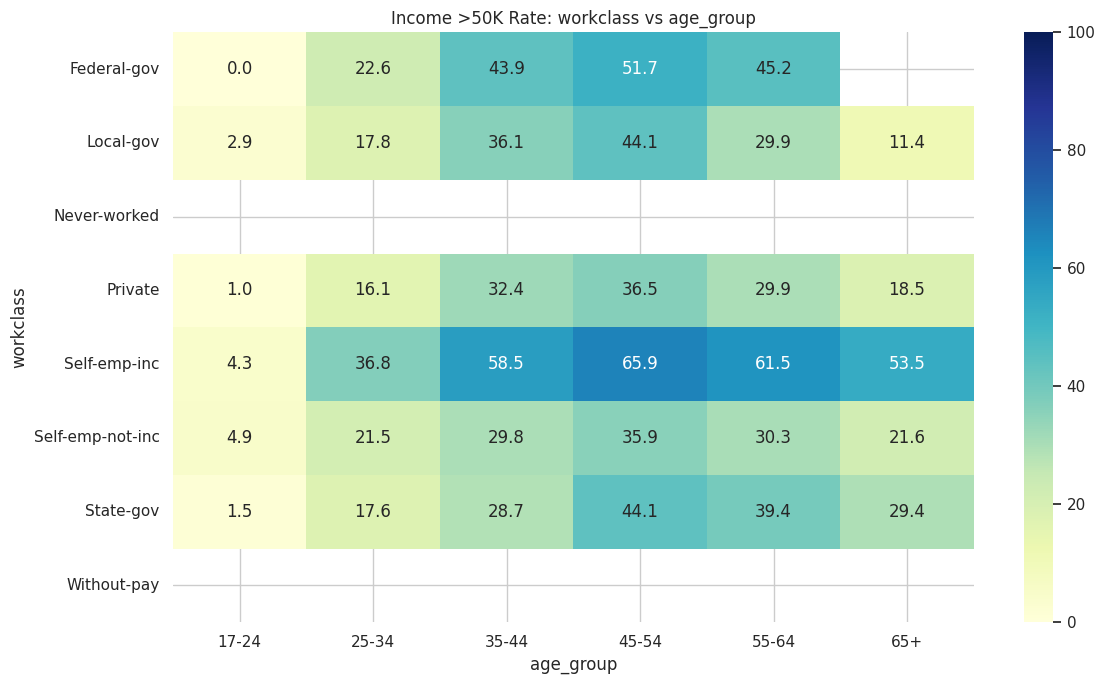

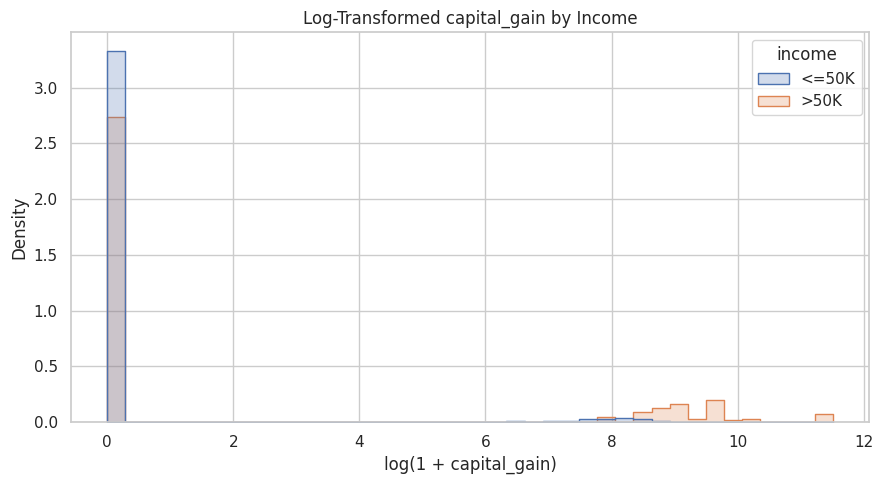

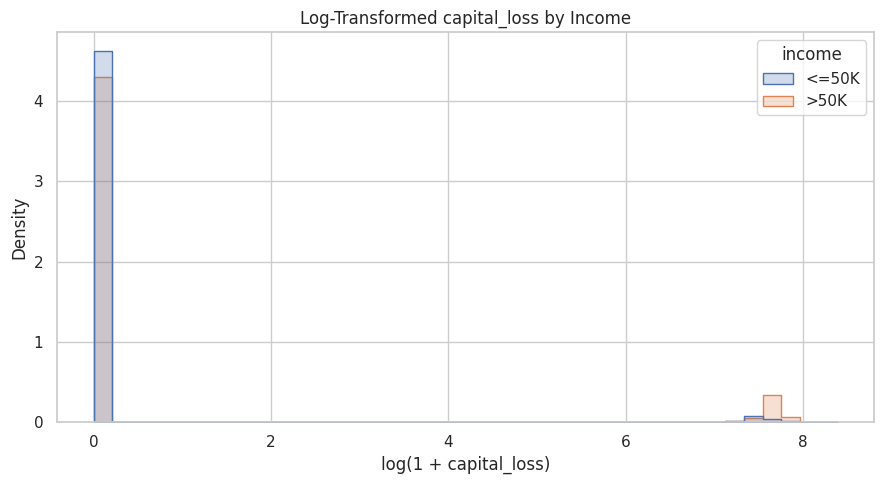

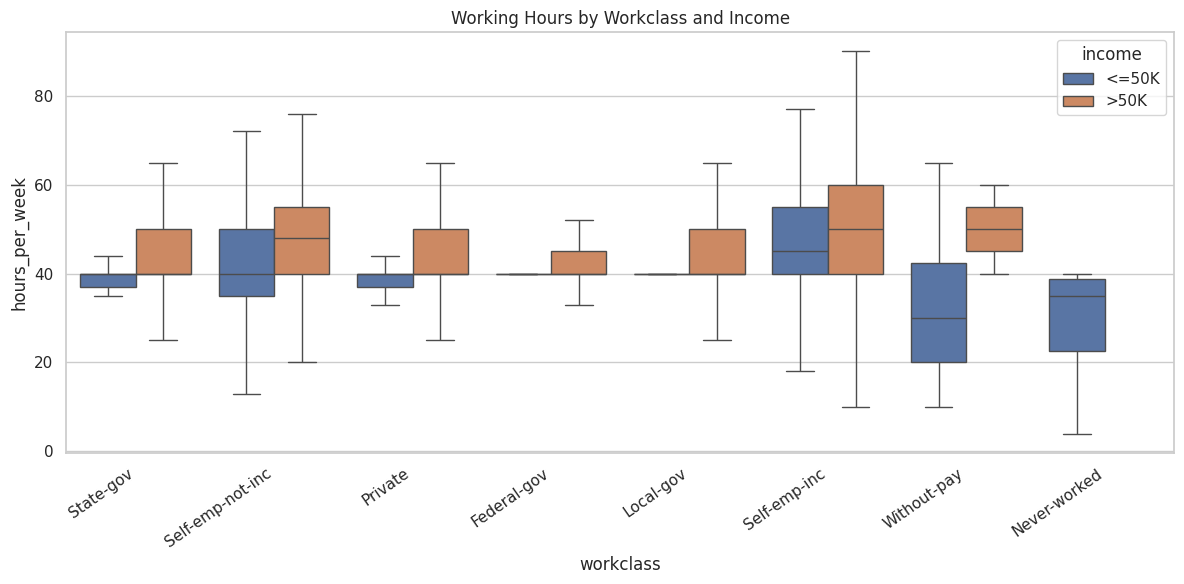


Saved interaction charts and reports to:
/content/interaction_eda_outputs


In [6]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Load dataset
df = pd.read_csv("adult_combined.csv", skipinitialspace=True)

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()

df.replace("?", np.nan, inplace=True)
df["income"] = df["income"].str.rstrip(".")
df["high_income"] = (df["income"] == ">50K").astype(int)

out = Path("interaction_eda_outputs")
out.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid")

# --------------------------------------------------
# 1. Create age groups
# --------------------------------------------------
df["age_group"] = pd.cut(
    df["age"],
    bins=[16, 25, 35, 45, 55, 65, 100],
    labels=["17-24", "25-34", "35-44", "45-54", "55-64", "65+"],
    right=False
)

# --------------------------------------------------
# 2. Education vs age group
# --------------------------------------------------
def plot_income_heatmap(row, col, min_count=50):
    grouped = (
        df.groupby([row, col], observed=True)
        .agg(
            total=("high_income", "size"),
            high_income_count=("high_income", "sum"),
            income_rate=("high_income", "mean")
        )
        .reset_index()
    )

    grouped["income_rate_pct"] = grouped["income_rate"] * 100
    grouped.to_csv(
        out / f"{row}_vs_{col}_income_rates.csv",
        index=False
    )

    # Exclude combinations with very few observations
    grouped.loc[
        grouped["total"] < min_count, "income_rate_pct"
    ] = np.nan

    pivot = grouped.pivot(
        index=row,
        columns=col,
        values="income_rate_pct"
    )

    plt.figure(figsize=(12, 7))
    sns.heatmap(
        pivot,
        annot=True,
        fmt=".1f",
        cmap="YlGnBu",
        vmin=0,
        vmax=100
    )
    plt.title(f"Income >50K Rate: {row} vs {col}")
    plt.tight_layout()
    plt.savefig(
        out / f"{row}_vs_{col}_heatmap.png",
        dpi=150
    )
    plt.show()
    plt.close()

plot_income_heatmap("education", "age_group", min_count=50)
plot_income_heatmap("education", "occupation", min_count=50)
plot_income_heatmap("workclass", "age_group", min_count=50)

# --------------------------------------------------
# 3. Capital gain/loss distributions
# Use log1p because these features are highly skewed
# --------------------------------------------------
for feature in ["capital_gain", "capital_loss"]:
    df[f"log_{feature}"] = np.log1p(df[feature])

    plt.figure(figsize=(9, 5))
    sns.histplot(
        data=df,
        x=f"log_{feature}",
        hue="income",
        bins=40,
        element="step",
        stat="density",
        common_norm=False
    )
    plt.title(f"Log-Transformed {feature} by Income")
    plt.xlabel(f"log(1 + {feature})")
    plt.tight_layout()
    plt.savefig(out / f"{feature}_income_distribution.png", dpi=150)
    plt.show()
    plt.close()

# --------------------------------------------------
# 4. Workclass vs working hours
# --------------------------------------------------
plt.figure(figsize=(12, 6))
sns.boxplot(
    data=df,
    x="workclass",
    y="hours_per_week",
    hue="income",
    showfliers=False
)
plt.xticks(rotation=35, ha="right")
plt.title("Working Hours by Workclass and Income")
plt.tight_layout()
plt.savefig(out / "workclass_hours_income.png", dpi=150)
plt.show()
plt.close()

# --------------------------------------------------
# 5. Numeric summary by income
# --------------------------------------------------
features = [
    "age",
    "fnlwgt",
    "education_num",
    "capital_gain",
    "capital_loss",
    "hours_per_week"
]

summary = df.groupby("income")[features].agg(
    ["mean", "median", "std"]
)
summary.to_csv(out / "numeric_summary_by_income.csv")

print("\nSaved interaction charts and reports to:")
print(out.resolve())


In [ ]:
#================================
# Prediction Main Model Training
#================================

DATA LOADING
Official training shape: (32561, 19)
Official test shape: (16281, 19)

Training income distribution:
income
<=50K    24720
>50K      7841
Name: count, dtype: int64

Official test income distribution:
income
<=50K    12435
>50K      3846
Name: count, dtype: int64

DATA QUALITY CHECKS

Missing values in training data:
workclass         1836
occupation        1843
native_country     583
dtype: int64

Duplicate rows in training data: 24
Duplicate rows in test data: 5

Training subset: (26048, 17)
Validation subset: (6513, 17)
Final test set: (16281, 17)

TUNING XGBOOST (RandomizedSearchCV, scoring = PR-AUC)
Fitting 3 folds for each of 20 candidates, totalling 60 fits
Best CV PR-AUC: 0.8293
Best params:
  subsample: 1.0
  reg_lambda: 0.5
  n_estimators: 600
  min_child_weight: 1
  max_depth: 5
  learning_rate: 0.03
  gamma: 0.1
  colsample_bytree: 0.8

TRAINING: Logistic Regression
accuracy    : 0.8595
precision   : 0.7479
recall      : 0.6282
f1          : 0.6828
roc_auc     :

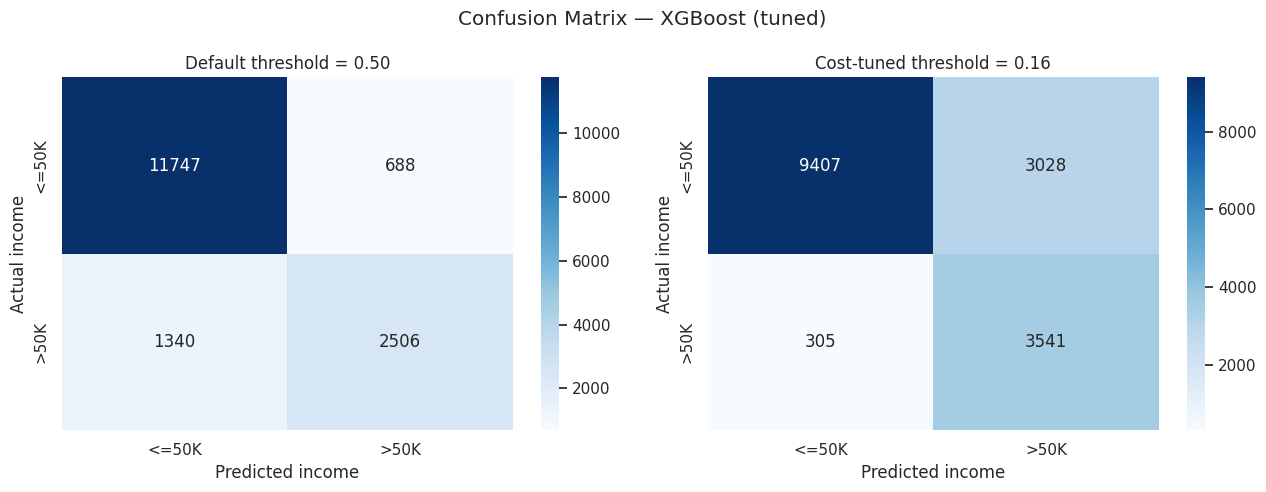


Model + threshold saved to: /content/adult_ml_outputs/adult_income_model.joblib
Reports saved to: /content/adult_ml_outputs

Training and evaluation completed.


In [10]:
# ============================================================
# UCI ADULT INCOME: CLEANING, TRAINING & EVALUATION (XGBoost)
# Focus: reduce False Negatives (missed >50K) via
#        a stronger model + cost-based threshold tuning
# ============================================================
# Install first (Colab):  !pip install xgboost

import json
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from xgboost import XGBClassifier

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    RandomizedSearchCV,
    cross_val_predict,
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
)

warnings.filterwarnings("ignore", category=FutureWarning)

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

DATA_DIR = Path("/content")  # Change if your files are elsewhere
OUTPUT_DIR = DATA_DIR / "adult_ml_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_FILE = DATA_DIR / "adult.data"
TEST_FILE = DATA_DIR / "adult.test"

RANDOM_STATE = 42

# Cost of each error type. A False Negative (missing a >50K person)
# is treated as 5x worse than a False Positive. Adjust to your problem.
COST_FN = 5
COST_FP = 1

# Set to True to also run a hyperparameter search for XGBoost
# (adds a few minutes, usually gives a small gain).
RUN_XGB_TUNING = True

COLUMNS = [
    "age", "workclass", "fnlwgt", "education",
    "education_num", "marital_status", "occupation",
    "relationship", "race", "sex", "capital_gain",
    "capital_loss", "hours_per_week", "native_country",
    "income"
]

NUMERIC_FEATURES = [
    "age", "fnlwgt", "education_num",
    "capital_gain", "capital_loss", "hours_per_week",
    # engineered
    "capital_gain_log", "capital_loss_log",
    "has_capital_gain", "has_capital_loss",
]

# "education" is dropped because "education_num" encodes the same info
CATEGORICAL_FEATURES = [
    "workclass", "marital_status",
    "occupation", "relationship", "race",
    "sex", "native_country"
]

# ------------------------------------------------------------
# 2. LOAD OFFICIAL TRAIN AND TEST FILES
# ------------------------------------------------------------

def add_features(df):
    """Simple feature engineering (no leakage: row-wise only)."""
    df = df.copy()
    df["capital_gain_log"] = np.log1p(df["capital_gain"])
    df["capital_loss_log"] = np.log1p(df["capital_loss"])
    df["has_capital_gain"] = (df["capital_gain"] > 0).astype(int)
    df["has_capital_loss"] = (df["capital_loss"] > 0).astype(int)
    return df


def load_adult_file(path, is_test=False):
    if not path.exists():
        raise FileNotFoundError(
            f"File not found: {path}\n"
            "Check DATA_DIR and ensure adult.data/adult.test exist."
        )

    data = pd.read_csv(
        path,
        header=None,
        names=COLUMNS,
        skipinitialspace=True,
        comment="|" if is_test else None
    )

    # Normalize whitespace and missing-value markers
    for col in data.select_dtypes(include="object").columns:
        data[col] = data[col].str.strip()

    data.replace("?", np.nan, inplace=True)

    # adult.test labels end with a period
    data["income"] = data["income"].str.rstrip(".")

    # Remove invalid target labels, if any
    data = data[data["income"].isin(["<=50K", ">50K"])].copy()

    return add_features(data.reset_index(drop=True))


train_df = load_adult_file(TRAIN_FILE)
test_df = load_adult_file(TEST_FILE, is_test=True)

print("=" * 65)
print("DATA LOADING")
print("=" * 65)
print("Official training shape:", train_df.shape)
print("Official test shape:", test_df.shape)

print("\nTraining income distribution:")
print(train_df["income"].value_counts())

print("\nOfficial test income distribution:")
print(test_df["income"].value_counts())

# ------------------------------------------------------------
# 3. DATA QUALITY CHECKS
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("DATA QUALITY CHECKS")
print("=" * 65)

print("\nMissing values in training data:")
print(train_df.isnull().sum()[lambda x: x > 0])

print("\nDuplicate rows in training data:", train_df.duplicated().sum())
print("Duplicate rows in test data:", test_df.duplicated().sum())

# Keep the official split and rows as-is (reproducible benchmark).

FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

X_train_full = train_df[FEATURES]
y_train_full = (train_df["income"] == ">50K").astype(int)

X_test = test_df[FEATURES]
y_test = (test_df["income"] == ">50K").astype(int)

# ------------------------------------------------------------
# 4. VALIDATION SPLIT (FROM TRAINING DATA ONLY)
# ------------------------------------------------------------

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.20,
    stratify=y_train_full,
    random_state=RANDOM_STATE
)

print("\nTraining subset:", X_train.shape)
print("Validation subset:", X_val.shape)
print("Final test set:", X_test.shape)

# ------------------------------------------------------------
# 5. PREPROCESSING PIPELINE
# ------------------------------------------------------------

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=True))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, NUMERIC_FEATURES),
    ("categorical", categorical_pipeline, CATEGORICAL_FEATURES)
])

# ------------------------------------------------------------
# 6. DEFINE MODELS
# ------------------------------------------------------------

def make_xgb(**overrides):
    params = dict(
        n_estimators=400,
        learning_rate=0.05,
        max_depth=6,
        min_child_weight=1,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        n_jobs=-1,
        random_state=RANDOM_STATE,
    )
    params.update(overrides)
    return XGBClassifier(**params)


models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1500,
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),

    "XGBoost": make_xgb(),
}

# ------------------------------------------------------------
# 6b. OPTIONAL: TUNE XGBOOST (training subset only)
# ------------------------------------------------------------

if RUN_XGB_TUNING:
    print("\n" + "=" * 65)
    print("TUNING XGBOOST (RandomizedSearchCV, scoring = PR-AUC)")
    print("=" * 65)

    search_pipe = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", make_xgb())
    ])

    param_dist = {
        "classifier__n_estimators": [200, 300, 400, 600],
        "classifier__learning_rate": [0.03, 0.05, 0.08, 0.1],
        "classifier__max_depth": [3, 4, 5, 6, 8],
        "classifier__min_child_weight": [1, 3, 5],
        "classifier__subsample": [0.7, 0.8, 0.9, 1.0],
        "classifier__colsample_bytree": [0.6, 0.8, 1.0],
        "classifier__reg_lambda": [0.5, 1, 3, 5],
        "classifier__gamma": [0, 0.1, 0.3],
    }

    search = RandomizedSearchCV(
        search_pipe,
        param_distributions=param_dist,
        n_iter=20,
        scoring="average_precision",
        cv=StratifiedKFold(n_splits=3, shuffle=True,
                           random_state=RANDOM_STATE),
        n_jobs=1,          # XGBoost already uses all cores
        random_state=RANDOM_STATE,
        verbose=1
    )
    search.fit(X_train, y_train)

    print("Best CV PR-AUC:", round(search.best_score_, 4))
    print("Best params:")
    for k, v in search.best_params_.items():
        print(f"  {k.replace('classifier__', '')}: {v}")

    models["XGBoost (tuned)"] = clone(
        search.best_estimator_.named_steps["classifier"]
    )

# ------------------------------------------------------------
# 7. TRAIN AND COMPARE ON VALIDATION DATA
# ------------------------------------------------------------

results = []
trained_models = {}

for name, classifier in models.items():
    print("\n" + "=" * 65)
    print(f"TRAINING: {name}")
    print("=" * 65)

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", clone(classifier))
    ])

    pipeline.fit(X_train, y_train)

    val_pred = pipeline.predict(X_val)
    val_prob = pipeline.predict_proba(X_val)[:, 1]

    tn, fp, fn, tp = confusion_matrix(y_val, val_pred).ravel()

    metrics = {
        "model": name,
        "accuracy": accuracy_score(y_val, val_pred),
        "precision": precision_score(y_val, val_pred, zero_division=0),
        "recall": recall_score(y_val, val_pred, zero_division=0),
        "f1": f1_score(y_val, val_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_val, val_prob),
        "pr_auc": average_precision_score(y_val, val_prob),
        "FN@0.5": fn,
        "FP@0.5": fp,
    }

    results.append(metrics)
    trained_models[name] = pipeline

    for metric, value in metrics.items():
        if metric != "model":
            print(f"{metric:12s}: {value:.4f}")

# ------------------------------------------------------------
# 8. SELECT BEST MODEL USING VALIDATION PR-AUC
# ------------------------------------------------------------

results_df = pd.DataFrame(results).sort_values("pr_auc", ascending=False)

print("\n" + "=" * 65)
print("VALIDATION MODEL COMPARISON")
print("=" * 65)
print(results_df.round(4).to_string(index=False))

results_df.to_csv(OUTPUT_DIR / "validation_model_comparison.csv", index=False)

best_name = results_df.iloc[0]["model"]
print(f"\nSelected model: {best_name}")

# ------------------------------------------------------------
# 9. RETRAIN SELECTED MODEL ON ALL OFFICIAL TRAINING DATA
# ------------------------------------------------------------

final_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", clone(models[best_name]))
])

final_model.fit(X_train_full, y_train_full)


# ------------------------------------------------------------
# 10. OOF THRESHOLD COMPARISON + COST-BASED SELECTION
# ------------------------------------------------------------
# OOF = Out-of-Fold predictions.
# Each training record gets a probability from a model that
# did not train on that record.
#
# Threshold selection uses training data only.
# The official test set is NOT used to choose the threshold.

print("\n" + "=" * 75)
print("THRESHOLD TUNING: 5-FOLD OUT-OF-FOLD PREDICTIONS")
print("=" * 75)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

oof_prob = cross_val_predict(
    clone(final_model),
    X_train_full,
    y_train_full,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

y_oof = np.asarray(y_train_full)
oof_prob = np.asarray(oof_prob)

# Thresholds to compare:
# Fine-grained search from 0.05 to 0.95, plus key thresholds.
thresholds = np.unique(np.round(np.concatenate([
    np.arange(0.05, 0.951, 0.01),
    [0.16, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]
]), 2))

oof_results = []

for t in thresholds:
    pred = (oof_prob >= t).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_oof,
        pred,
        labels=[0, 1]
    ).ravel()

    precision = precision_score(
        y_oof, pred, zero_division=0
    )
    recall = recall_score(
        y_oof, pred, zero_division=0
    )
    f1 = f1_score(
        y_oof, pred, zero_division=0
    )
    f2 = fbeta_score(
        y_oof, pred, beta=2, zero_division=0
    )
    accuracy = accuracy_score(y_oof, pred)

    # Cost: FN is 5x as expensive as FP
    total_cost = COST_FN * fn + COST_FP * fp

    oof_results.append({
        "threshold": float(t),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "f2": f2,
        "TP": int(tp),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "total_cost": int(total_cost)
    })

oof_threshold_df = pd.DataFrame(oof_results)

# Select the threshold with the lowest weighted error cost.
# If costs tie, prefer higher F1.
oof_threshold_df = oof_threshold_df.sort_values(
    ["total_cost", "f1"],
    ascending=[True, False]
).reset_index(drop=True)

best_row = oof_threshold_df.iloc[0]
threshold = float(best_row["threshold"])

# Save all threshold comparisons.
oof_threshold_path = OUTPUT_DIR / "oof_threshold_comparison.csv"
oof_threshold_df.to_csv(oof_threshold_path, index=False)

# Show selected practical thresholds in ascending order.
display_thresholds = [
    0.16, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50
]

comparison = (
    oof_threshold_df[
        oof_threshold_df["threshold"].isin(display_thresholds)
    ]
    .sort_values("threshold")
)

print(f"\nCost ratio: FN={COST_FN}x, FP={COST_FP}x")
print("\nOOF threshold comparison:")
print(comparison.round(4).to_string(index=False))

print("\n" + "-" * 75)
print("BEST COST-BASED OOF THRESHOLD")
print("-" * 75)
print(f"Selected threshold : {threshold:.2f}")
print(f"Accuracy            : {best_row['accuracy']:.4f}")
print(f"Precision           : {best_row['precision']:.4f}")
print(f"Recall              : {best_row['recall']:.4f}")
print(f"F1                  : {best_row['f1']:.4f}")
print(f"F2                  : {best_row['f2']:.4f}")
print(f"TP                  : {int(best_row['TP'])}")
print(f"TN                  : {int(best_row['TN'])}")
print(f"FP                  : {int(best_row['FP'])}")
print(f"FN                  : {int(best_row['FN'])}")
print(f"Weighted cost       : {int(best_row['total_cost'])}")

# Also report the threshold that maximizes F2, for reference.
f2_best_row = oof_threshold_df.loc[
    oof_threshold_df["f2"].idxmax()
]

threshold_f2 = float(f2_best_row["threshold"])

print(f"\nF2-maximizing threshold: {threshold_f2:.2f}")
print(f"F2 at that threshold   : {f2_best_row['f2']:.4f}")

print(f"\nFull threshold table saved to: {oof_threshold_path}")


# ------------------------------------------------------------
# 11. FINAL EVALUATION ON OFFICIAL TEST DATA
# ------------------------------------------------------------

test_prob = final_model.predict_proba(X_test)[:, 1]


def evaluate(y_true, prob, thr):
    pred = (prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred).ravel()
    return {
        "threshold": round(float(thr), 2),
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "f2": fbeta_score(y_true, pred, beta=2),
        "TP": tp, "TN": tn, "FP": fp, "FN": fn,
        "total_cost": COST_FN * fn + COST_FP * fp,
    }, pred


default_metrics, default_pred = evaluate(y_test, test_prob, 0.5)
tuned_metrics, tuned_pred = evaluate(y_test, test_prob, threshold)

compare_df = pd.DataFrame(
    [default_metrics, tuned_metrics],
    index=["Default (0.50)", "Cost-tuned"]
)

print("\n" + "=" * 65)
print(f"FINAL OFFICIAL TEST RESULTS — {best_name}")
print("=" * 65)
print(compare_df.round(4).T.to_string())

print(f"\nROC-AUC: {roc_auc_score(y_test, test_prob):.4f}")
print(f"PR-AUC : {average_precision_score(y_test, test_prob):.4f}")

print("\nClassification report (cost-tuned threshold):")
print(classification_report(
    y_test,
    tuned_pred,
    target_names=["<=50K", ">50K"],
    zero_division=0
))

compare_df.to_csv(OUTPUT_DIR / "final_test_metrics.csv")

# ------------------------------------------------------------
# 12. CONFUSION MATRICES (DEFAULT vs TUNED)
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, pred, title in [
    (axes[0], default_pred, "Default threshold = 0.50"),
    (axes[1], tuned_pred, f"Cost-tuned threshold = {threshold:.2f}"),
]:
    sns.heatmap(
        confusion_matrix(y_test, pred),
        annot=True, fmt="d", cmap="Blues", ax=ax,
        xticklabels=["<=50K", ">50K"],
        yticklabels=["<=50K", ">50K"]
    )
    ax.set_xlabel("Predicted income")
    ax.set_ylabel("Actual income")
    ax.set_title(title)

plt.suptitle(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=150)
plt.show()
plt.close()

# ------------------------------------------------------------
# 13. SAVE MODEL + THRESHOLD
# ------------------------------------------------------------

model_path = OUTPUT_DIR / "adult_income_model.joblib"
joblib.dump({"model": final_model, "threshold": float(threshold)}, model_path)

with open(OUTPUT_DIR / "threshold.json", "w") as f:
    json.dump({
        "selected_model": best_name,
        "threshold": float(threshold),
        "cost_fn": COST_FN,
        "cost_fp": COST_FP,
    }, f, indent=2)

print("\nModel + threshold saved to:", model_path)
print("Reports saved to:", OUTPUT_DIR.resolve())
print("\nTraining and evaluation completed.")

# ------------------------------------------------------------
# HOW TO PREDICT LATER
# ------------------------------------------------------------
# bundle = joblib.load(model_path)
# prob = bundle["model"].predict_proba(new_df[FEATURES])[:, 1]
# pred = (prob >= bundle["threshold"]).astype(int)